# Лабораторная работа №3. Кластеризация

## Вариант: **Gene Expression Cancer Dataset** — кластеризация образцов тканей по экспрессии генов для выявления паттернов заболевания

**Цель работы:** изучить алгоритмы кластеризации, приобрести навыки оценки качества разбиения данных на кластеры и интерпретации результатов.

**Задачи работы:**

1. Загрузить датасет, выполнить дескриптивный анализ: размерность, типы признаков, пропуски.
2. Оценить распределение переменных (близость к нормальному), выбросы и информационную значимость признаков.
3. Проверить условия применимости кластеризации: отсутствие классов, осмысленность (кластеризуемость), отсутствие выбросов.
4. Выполнить стандартизацию числовых признаков и обосновать выбор метода масштабирования; при необходимости снизить размерность (PCA).
5. Построить матрицу диаграмм рассеяния и аргументированно выбрать методы кластеризации по форме, размеру и плотности кластеров.
6. Реализовать кластеризацию двумя методами — **K-means** и **иерархической кластеризацией (метод Уорда)**; подобрать число кластеров $k$ методом локтя и анализом силуэта, построить дендрограмму.
7. Рассчитать внутренние и внешние метрики качества, оценить внутрикластерные расстояния, расстояния между кластерами, компактность и центры кластеров.
8. Исследовать влияние параметров ($k$ для K-means; $\varepsilon$ и `min_samples` для DBSCAN) и устойчивость кластеров.
9. Визуализировать кластеры (PCA), интерпретировать центры кластеров, сравнить два метода.

**Данные:** файл `df_combined.csv` — микрочип-профили экспрессии **1935 генных зондов** (log2-интенсивности) для **62 образцов** опухолей толстой и прямой кишки, а также клинические данные (возраст, стадия по Дьюку, пол, локализация, выживаемость без рецидива, адъювантная терапия).

> Все эксперименты воспроизводимы: фиксируется `RANDOM_STATE = 42`. Клинические признаки **не участвуют в кластеризации** — они используются только для внешней валидации и интерпретации результатов.

## 1. Импорт библиотек и настройка окружения

Используются: **Pandas/NumPy** (обработка данных), **SciPy** (статистические тесты, иерархическая кластеризация, расстояния), **Scikit-Learn** (стандартизация, PCA, K-means, Ward, DBSCAN, метрики качества), **Matplotlib/Seaborn** (визуализация).

Для воспроизводимости фиксируется seed. Все рисунки сохраняются в каталог `figures_clustering/`, итоговые таблицы — в `results_clustering/`.

In [1]:
from pathlib import Path
import os
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import cdist, pdist

import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score, silhouette_samples, calinski_harabasz_score,
    davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score,
    homogeneity_score, completeness_score, fowlkes_mallows_score,
    pair_confusion_matrix,
)

RANDOM_STATE = 42
RS = RANDOM_STATE
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "font.size": 10,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

FIG_DIR = Path("figures_clustering")
FIG_DIR.mkdir(exist_ok=True)
RESULT_DIR = Path("results_clustering")
RESULT_DIR.mkdir(exist_ok=True)

def save_fig(name):
    """Сохраняет текущий рисунок в figures_clustering/<name>.png"""
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

NumPy: 2.5.4
Pandas: 3.0.6
scikit-learn: 1.9.1

## 2. Описание датасета

### 2.1. Общая характеристика

**Gene Expression Cancer Dataset** — набор данных по экспрессии генов в образцах опухолевой ткани. Задача кластеризации: по уровням экспрессии сгруппировать образцы так, чтобы выявить возможные молекулярные паттерны заболевания без использования известных меток.

| Свойство | Значение |
|:---|:---|
| Число образцов (объектов) | 62 |
| Число генных зондов (признаков) | 1935 (log2-интенсивности) |
| Клинические переменные | 8 (3 категориальных и 5 числовых) |
| Идентификатор образца | `ID_REF` (GSM-номер GEO) |
| Пропуски | отсутствуют |
| Соотношение объектов и признаков | $n \ll p$ (62 против 1935) |

Главная особенность данных — **«проклятие размерности»**: признаков в 30 раз больше, чем объектов. Это сильно влияет на выбор методов и подготовку данных.

### 2.2. Описание признаков

| Группа | Признаки | Тип | Роль в работе |
|:---|:---|:---|:---|
| Экспрессия генов | 1935 столбцов вида `117_at`, `1007_s_at`, … | float (log2) | **признаки для кластеризации** |
| Стадия | `Dukes Stage` (A/B/C/D) | категориальный | внешняя валидация |
| Пол | `Gender` | категориальный | внешняя валидация |
| Локализация | `Location` (Left/Right/Rectum/Colon) | категориальный | внешняя валидация |
| Возраст | `Age (in years)` | числовой | интерпретация |
| Выживаемость без рецидива | `DFS (in months)`, `DFS event` | числовой / бинарный | интерпретация |
| Терапия | `Adj_Radio`, `Adj_Chem` | бинарные | интерпретация |
| Служебные | `Unnamed: 0`, `ID_REF` | индекс / идентификатор | индекс таблицы |

### 2.3. Загрузка данных

В Google Colab при первом запуске ноутбук предложит загрузить файл `df_combined.csv` (диалог выбора файла). При локальном запуске файл должен лежать рядом с ноутбуком.

In [2]:
try:
    from google.colab import files
    if not os.path.exists("df_combined.csv"):
        print("Загрузите файл df_combined.csv")
        files.upload()
except ImportError:
    pass   # локальный запуск

PATH = "df_combined.csv" if os.path.exists("df_combined.csv") else "/mnt/user-data/uploads/df_combined.csv"
df = pd.read_csv(PATH, index_col=0).set_index("ID_REF")

meta_cols = ["Age (in years)", "Dukes Stage", "Gender", "Location",
             "DFS (in months)", "DFS event", "Adj_Radio", "Adj_Chem"]
gene_cols = [c for c in df.columns if c not in meta_cols]
meta, X = df[meta_cols], df[gene_cols]

print("Размерность таблицы:", df.shape)
print(f"Образцов: {X.shape[0]}, генных зондов (признаков): {X.shape[1]}")
print("\nТипы данных:")
print(df.dtypes.astype(str).value_counts().to_string())
print("\nПропусков всего:", int(df.isna().sum().sum()), "| дубликатов строк:", int(df.duplicated().sum()))
print("Диапазон экспрессии (log2): от", round(X.values.min(), 2), "до", round(X.values.max(), 2))

Размерность таблицы: (62, 1943)
Образцов: 62, генных зондов (признаков): 1935

Типы данных:
float64    1940
str           3

Пропусков всего: 0 | дубликатов строк: 0
Диапазон экспрессии (log2): от 2.23 до 14.86

In [3]:
# Сводная информация по клиническим переменным
summary = pd.DataFrame({
    "dtype": meta.dtypes.astype(str),
    "non_null": meta.notna().sum(),
    "missing": meta.isna().sum(),
    "unique": meta.nunique(),
})
display(summary)
display(meta.describe().T.round(2))
for c in ["Dukes Stage", "Gender", "Location", "DFS event", "Adj_Radio", "Adj_Chem"]:
    print(f"{c:12s}", meta[c].value_counts().to_dict())

Dukes Stage  {'C': 20, 'A': 16, 'B': 14, 'D': 12}
Gender       {'Male': 48, 'Female': 14}
Location     {'Right': 22, 'Left': 20, 'Rectum': 18, 'Colon': 2}
DFS event    {1.0: 37, 0.0: 25}
Adj_Radio    {1.0: 33, 0.0: 29}
Adj_Chem     {0.0: 32, 1.0: 30}

,dtype,non_null,missing,unique
Age (in years),float64,62,0,33
Dukes Stage,str,62,0,4
Gender,str,62,0,2
Location,str,62,0,4
DFS (in months),float64,62,0,44
DFS event,float64,62,0,2
Adj_Radio,float64,62,0,2
Adj_Chem,float64,62,0,2


,count,mean,std,min,25%,50%,75%,max
Age (in years),62.0,61.11,9.58,28.0,56.25,62.0,67.0,78.0
DFS (in months),62.0,41.77,26.29,4.0,19.50,38.0,57.5,108.0
DFS event,62.0,0.60,0.49,0.0,0.00,1.0,1.0,1.0
Adj_Radio,62.0,0.53,0.50,0.0,0.00,1.0,1.0,1.0
Adj_Chem,62.0,0.48,0.50,0.0,0.00,0.0,1.0,1.0


In [4]:
# Первые строки матрицы экспрессии
display(X.iloc[:5, :8])

,117_at,1007_s_at,1053_at,121_at,1255_g_at,1294_at,1316_at,1320_at
ID_REF,,,,,,,,
GSM877126,6.029834,9.468893,7.187090,6.807582,3.084591,7.397013,6.525426,3.848253
GSM877127,6.344321,9.994204,7.705626,6.893130,3.118704,7.163797,6.391195,4.202085
GSM877128,5.023127,10.409823,7.934057,7.165602,2.984632,7.375224,5.538846,4.074462
GSM877129,4.612727,10.596921,7.446374,7.071417,2.912851,7.596233,5.989148,3.738205
GSM877130,5.865944,10.252547,7.141105,7.103383,3.383726,7.278244,5.678236,4.141955



**Результаты дескриптивного анализа:**

- Размерность таблицы — **62 × 1943**: 62 образца, 1935 генных зондов и 8 клинических переменных (ещё один столбец — идентификатор `ID_REF`, использованный как индекс). Признаков в 30 раз больше, чем объектов.
- Все 1935 гена имеют тип `float64` (log2-интенсивности в диапазоне **2.23 – 14.86**), клинические переменные — 3 категориальных (`Dukes Stage`, `Gender`, `Location`) и 5 числовых.
- **Пропусков нет, дубликатов нет** — импутация не требуется.
- Клинический состав выборки: стадии Дьюка C — 20, A — 16, B — 14, D — 12; мужчин 48, женщин 14; локализация: Right 22, Left 20, Rectum 18, Colon 2; рецидив зарегистрирован у 37 из 62 пациентов; средний возраст 61 год (28–78), медиана выживаемости без рецидива 38 мес.
- Классы заметно несбалансированы по полу (77 % мужчин) и локализации (категория `Colon` — всего 2 образца), поэтому внешние метрики по этим признакам следует трактовать осторожно.


### 2.4. Распределение признаков

Кластеризация на евклидовых расстояниях не требует строгой нормальности, но сильная асимметрия и тяжёлые хвосты искажают расстояния. Оцениваем гистограммы 12 случайных генов, асимметрию (skewness) и тест Шапиро–Уилка по всем генам.

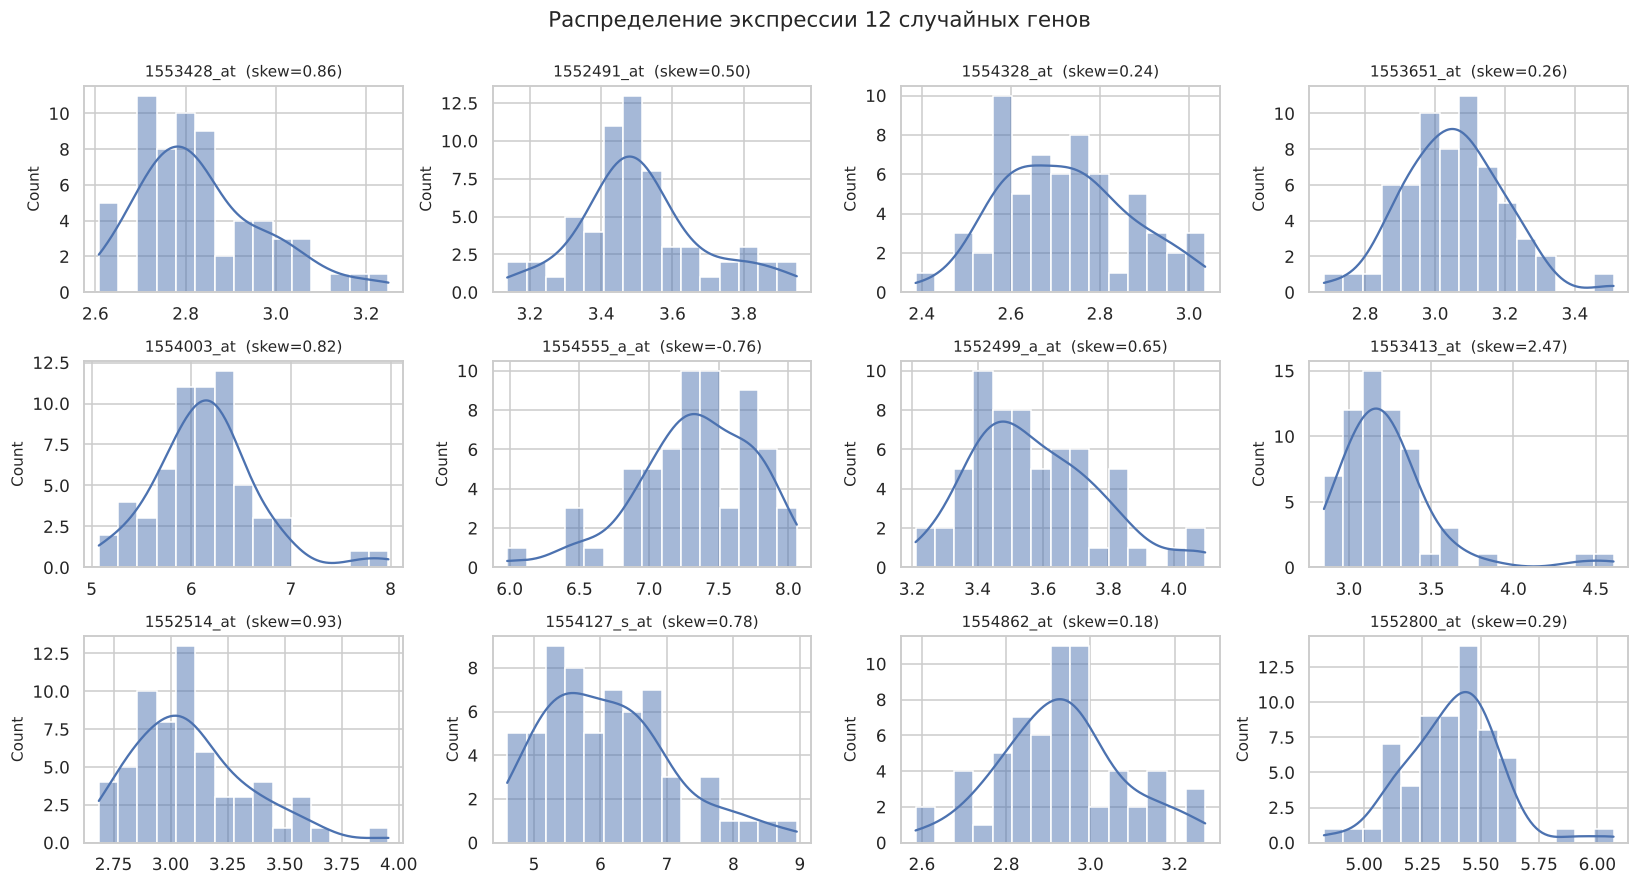

In [5]:
rng = np.random.default_rng(RANDOM_STATE)
sample_genes = rng.choice(gene_cols, 12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(15, 8))
for ax, g in zip(axes.ravel(), sample_genes):
    sns.histplot(X[g], kde=True, ax=ax, bins=15, color="#4c72b0")
    ax.set_title(f"{g}  (skew={X[g].skew():.2f})", fontsize=10)
    ax.set_xlabel("")
fig.suptitle("Распределение экспрессии 12 случайных генов", fontsize=14, y=1.0)
fig.tight_layout()
save_fig("01_gene_histograms")
plt.show()

Доля генов, для которых нормальность НЕ отвергается (Шапиро–Уилк, p > 0.05): 64.7%
Асимметрия: медиана = 0.39;  |skew| > 1 у 19.6% генов

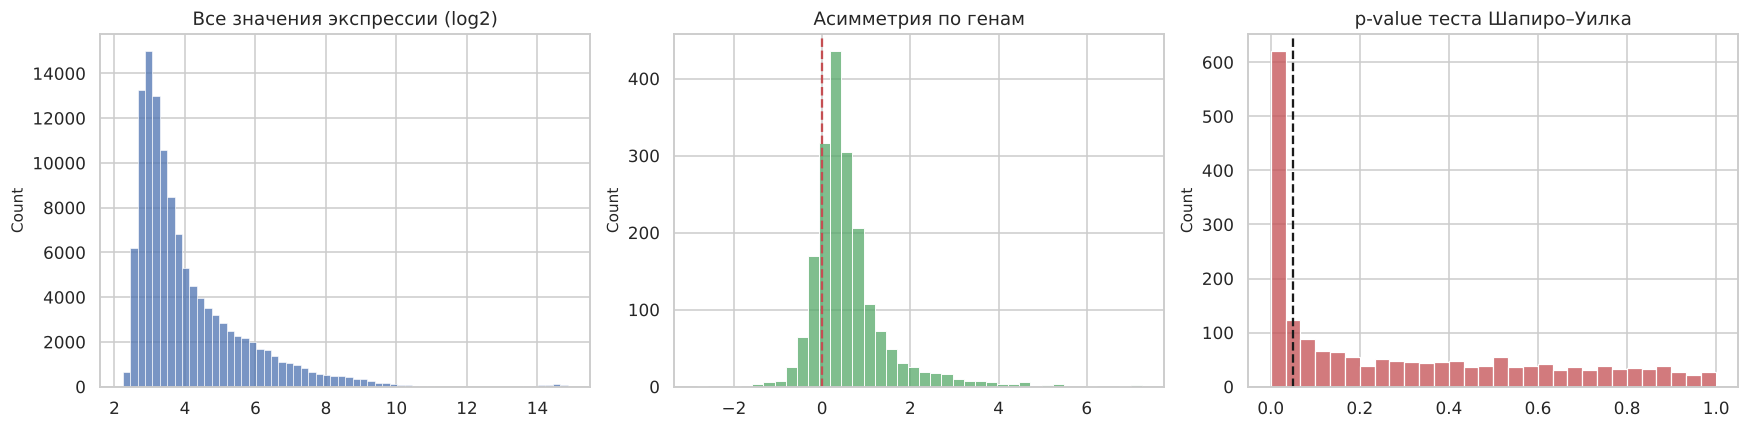

In [6]:
skew = X.skew()
sh_p = np.array([stats.shapiro(X[g])[1] for g in gene_cols])
print(f"Доля генов, для которых нормальность НЕ отвергается (Шапиро–Уилк, p > 0.05): {(sh_p > 0.05).mean():.1%}")
print(f"Асимметрия: медиана = {skew.median():.2f};  |skew| > 1 у {(skew.abs() > 1).mean():.1%} генов")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(X.values.ravel(), bins=60, ax=axes[0], color="#4c72b0")
axes[0].set_title("Все значения экспрессии (log2)")
sns.histplot(skew, bins=40, ax=axes[1], color="#55a868")
axes[1].set_title("Асимметрия по генам"); axes[1].axvline(0, c="r", ls="--")
sns.histplot(sh_p, bins=30, ax=axes[2], color="#c44e52")
axes[2].set_title("p-value теста Шапиро–Уилка"); axes[2].axvline(0.05, c="k", ls="--")
fig.tight_layout()
save_fig("02_distribution_summary")
plt.show()


**Выводы о распределениях:**

- Гистограммы отдельных генов в основном одновершинные и колоколообразные, но у части генов видна правая асимметрия (длинный правый хвост).
- По тесту Шапиро–Уилка нормальность не отвергается примерно для **64.7 %** генов; медиана асимметрии положительна (**0.39**), а у **19.6 %** генов $|skew| > 1$. Общая гистограмма всех значений — мультимодальная (гены с разным базовым уровнем экспрессии), что ожидаемо.
- Следовательно, данные **близки к нормальным, но не строго нормальны**. Для K-means и метода Уорда строгая нормальность не обязательна; главное — привести признаки к общему масштабу (раздел 3.1). Умеренную асимметрию частично компенсирует то, что данные уже представлены в log2-шкале.


### 2.5. Анализ выбросов

Выбросы анализируем тремя способами:

1. по отдельным значениям — правило $|z| > 3$ и правило $1.5 \cdot IQR$;
2. по образцам — число экстремальных значений у каждого образца и распределение экспрессии по образцам;
3. в многомерном смысле — расстояние образца от центра облака в пространстве главных компонент (раздел 3.3).

Доля значений с |z| > 3: 0.74%;  вне границ 1.5·IQR: 2.70%
Образцы с наибольшим числом экстремальных значений:

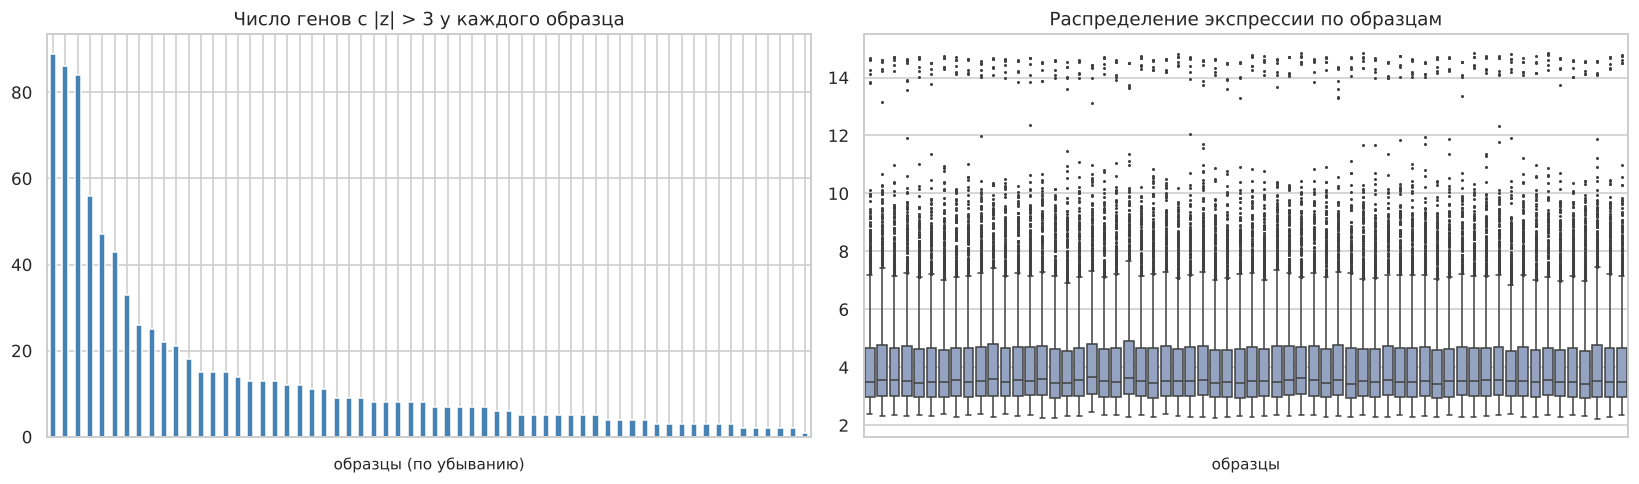

,genes_|z|>3
ID_REF,
GSM877147,89
GSM877144,86
GSM877186,84
GSM877142,56
GSM877127,47
GSM877153,43


In [7]:
Zr = (X - X.mean()) / X.std()
n_out = (Zr.abs() > 3).sum(axis=1)
q1, q3 = X.quantile(.25), X.quantile(.75)
iqr = q3 - q1
iqr_out = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).sum(axis=1)
print(f"Доля значений с |z| > 3: {(Zr.abs() > 3).values.mean():.2%};  вне границ 1.5·IQR: {iqr_out.sum() / X.size:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
n_out.sort_values(ascending=False).plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Число генов с |z| > 3 у каждого образца")
axes[0].set_xticklabels([]); axes[0].set_xlabel("образцы (по убыванию)")
sns.boxplot(data=X.T, ax=axes[1], fliersize=1, color="#8da0cb")
axes[1].set_title("Распределение экспрессии по образцам")
axes[1].set_xticklabels([]); axes[1].set_xlabel("образцы")
fig.tight_layout()
save_fig("03_outliers")
plt.show()

print("Образцы с наибольшим числом экстремальных значений:")
display(n_out.sort_values(ascending=False).head(6).to_frame("genes_|z|>3"))


**Выводы о выбросах:**

- По отдельным значениям выбросов немного: $|z| > 3$ у **0.74 %** значений, вне границ $1.5 \cdot IQR$ — **2.70 %**. Для 1935 признаков это обычный «шум» тяжёлых хвостов.
- На уровне **образцов** картина иная: три образца заметно выделяются числом экстремальных значений — **GSM877147 (89 генов), GSM877144 (86), GSM877186 (84)**; у следующего по порядку GSM877142 — 56. Эти образцы отличаются от остальных сразу по многим генам, то есть являются **многомерными выбросами** (возможные причины — иное качество РНК, состав ткани или батч-эффект).
- Решение: образцы **сохраняются** (удалить 3 из 62 объектов — значит потерять около 5 % выборки без биологического обоснования), но их влияние учитывается — см. раздел 3.3 и анализ $k \ge 3$ в разделе 5.5.1.


### 2.6. Информационная значимость признаков

Информативность гена для кластеризации определяется тем, насколько он **различает образцы**. Гены с почти постоянной экспрессией не несут информации о структуре. Оцениваем:

- **дисперсию** экспрессии (до стандартизации) и связь стандартного отклонения со средним;
- **взаимную корреляцию** генов — избыточность признаков (если признаки сильно коррелируют, их можно сжать PCA).

Гены с дисперсией < 0.05: 1055 (54.5%);  медиана дисперсии: 0.044
Пар генов с |r| > 0.7: 0.01%;  с |r| > 0.5: 0.26%

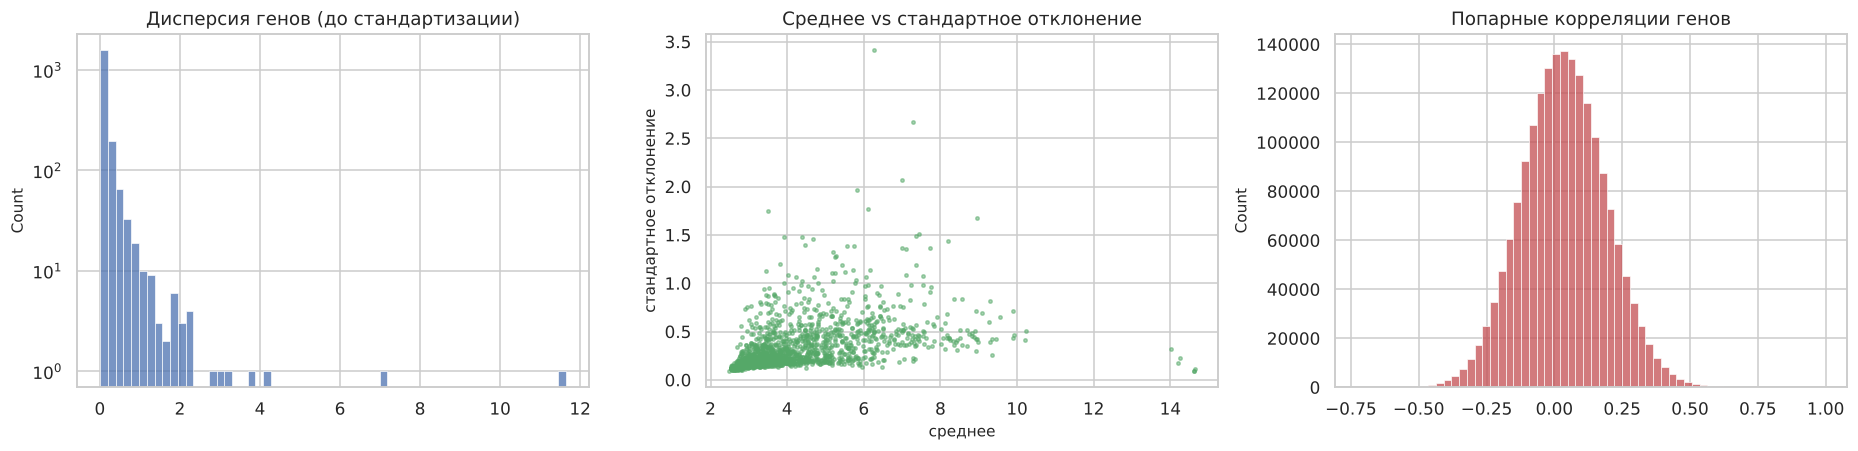

In [8]:
var = X.var()
corr = X.corr().values
iu = np.triu_indices_from(corr, 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.histplot(var, bins=60, ax=axes[0], color="#4c72b0")
axes[0].set_yscale("log"); axes[0].set_title("Дисперсия генов (до стандартизации)")
axes[1].scatter(X.mean(), X.std(), s=5, alpha=.5, color="#55a868")
axes[1].set_xlabel("среднее"); axes[1].set_ylabel("стандартное отклонение")
axes[1].set_title("Среднее vs стандартное отклонение")
sns.histplot(corr[iu], bins=60, ax=axes[2], color="#c44e52")
axes[2].set_title("Попарные корреляции генов")
fig.tight_layout()
save_fig("04_informativeness")
plt.show()

print(f"Гены с дисперсией < 0.05: {(var < 0.05).sum()} ({(var < 0.05).mean():.1%});  медиана дисперсии: {var.median():.3f}")
print(f"Пар генов с |r| > 0.7: {(np.abs(corr[iu]) > 0.7).mean():.2%};  с |r| > 0.5: {(np.abs(corr[iu]) > 0.5).mean():.2%}")


**Выводы об информативности признаков:**

- Дисперсия генов сильно смещена к малым значениям: медиана — **0.044**, а **1055 генов (54.5 %)** имеют дисперсию < 0.05 — их экспрессия почти не различается между образцами, и они вносят в расстояния в основном шум.
- Среднее и стандартное отклонение связаны слабо; есть небольшая группа высоковариабельных генов (std до 3.4).
- Гены между собой **почти не коррелируют**: пар с $|r| > 0.7$ всего **0.01 %**, с $|r| > 0.5$ — **0.26 %**. Это значит, что информация не сконцентрирована в нескольких блоках скоррелированных генов, а «размазана» по многим слабым сигналам. Отбор нескольких генов был бы произвольным, поэтому для сжатия применяется PCA (раздел 3.2).
- Итог: информативность признаков в целом невысока, а размерность избыточна — кластеризацию нужно выполнять в пространстве сжатых признаков и осторожно трактовать результаты в полном пространстве.


## 3. Предобработка данных

### 3.1. Выбор метода масштабирования

Данные уже логарифмированы (log2), поэтому разброс значений умеренный, однако стандартные отклонения генов различаются в десятки раз. K-means, метод Уорда и DBSCAN основаны на **евклидовом расстоянии**, поэтому гены с большой дисперсией доминировали бы в расстояниях.

| Метод | Преобразование | Почему подходит / не подходит |
|:---|:---|:---|
| **StandardScaler** | $z = (x - \mu)/\sigma$ | **выбран**: приводит все гены к единому масштабу (среднее 0, std 1); данные близки к нормальным; рекомендован заданием |
| MinMaxScaler | $(x - x_{min})/(x_{max} - x_{min})$ | не выбран: границы определяются крайними значениями и сильно страдают от выбросов |
| RobustScaler | $(x - \mathrm{med})/IQR$ | возможная альтернатива при сильных выбросах, но выбросов по генам мало |

Std генов ДО стандартизации:  min = 0.089, медиана = 0.210, max = 3.413
Std генов ПОСЛЕ стандартизации: min = 1.000, max = 1.000; max|mean| = 2.6e-14

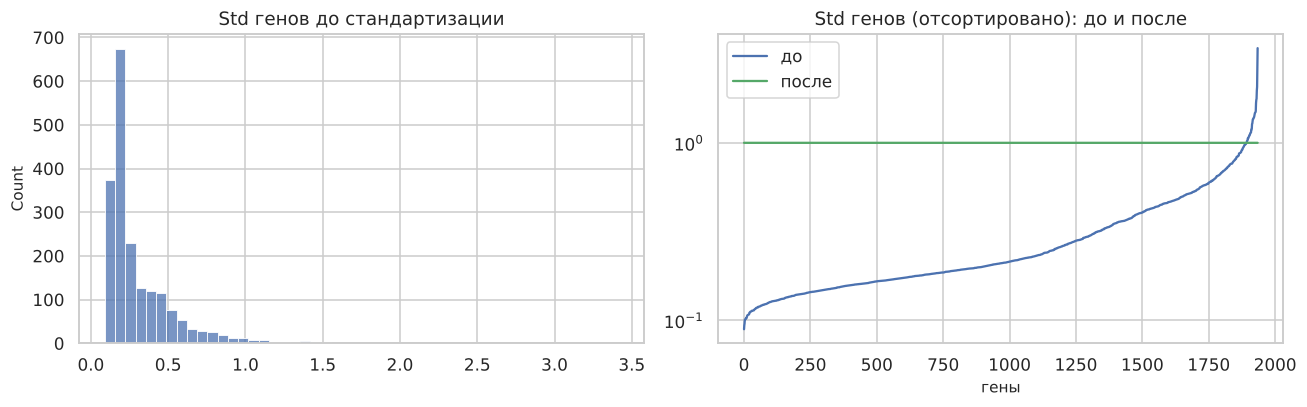

In [9]:
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

std_before = X.std()
print("Std генов ДО стандартизации:  min = %.3f, медиана = %.3f, max = %.3f" % (std_before.min(), std_before.median(), std_before.max()))
print("Std генов ПОСЛЕ стандартизации: min = %.3f, max = %.3f; max|mean| = %.1e" % (Xs.std(0).min(), Xs.std(0).max(), np.abs(Xs.mean(0)).max()))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(std_before, bins=50, ax=axes[0], color="#4c72b0"); axes[0].set_title("Std генов до стандартизации")
axes[1].plot(np.sort(std_before.values), label="до", c="#4c72b0")
axes[1].plot(np.sort(Xs.std(0)), label="после", c="#55a868")
axes[1].set_yscale("log"); axes[1].legend()
axes[1].set_title("Std генов (отсортировано): до и после"); axes[1].set_xlabel("гены")
fig.tight_layout()
save_fig("05_scaling")
plt.show()


**Результат масштабирования.** До стандартизации стандартные отклонения генов лежат в диапазоне **0.089 – 3.413** (медиана 0.210), то есть различаются почти в **40 раз**; после `StandardScaler` у всех генов среднее равно 0 (до $10^{-14}$) и std = 1. Теперь вклад каждого гена в евклидово расстояние сопоставим.

Побочное следствие: стандартизация одинаково усиливает вклад как информативных, так и «шумовых» генов с очень малой дисперсией (54.5 % генов). Это ещё одна причина, по которой после неё необходимо снижение размерности.


### 3.2. Снижение размерности (PCA)

При $p \gg n$ расстояния в исходном пространстве теряют контрастность («проклятие размерности»): расстояния между всеми парами точек становятся почти одинаковыми, и silhouette стремится к нулю. Поэтому дополнительно строим метод главных компонент и кластеризуем в пространстве первых ГК. Число компонент выбираем по scree-plot.

Накопленная дисперсия: 2 ГК = 13.8%, 5 ГК = 25.9%, 10 ГК = 37.5%; для 80% нужно 40 ГК
Форма матрицы в пространстве ГК: (62, 10)

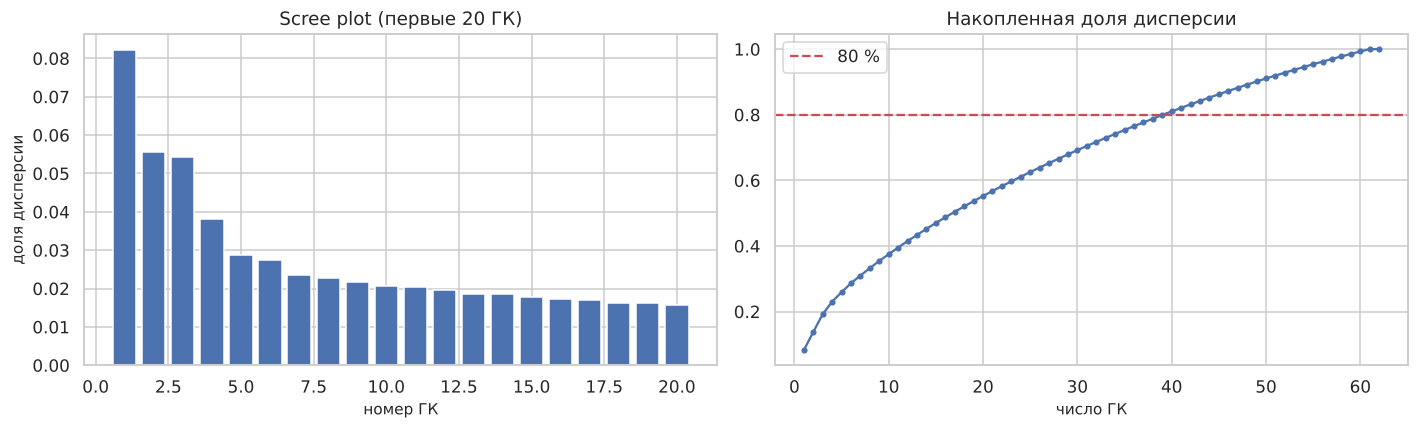

In [10]:
pca_full = PCA(random_state=RANDOM_STATE).fit(Xs)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(range(1, 21), evr[:20], color="#4c72b0")
axes[0].set_title("Scree plot (первые 20 ГК)"); axes[0].set_xlabel("номер ГК"); axes[0].set_ylabel("доля дисперсии")
axes[1].plot(range(1, len(cum) + 1), cum, "o-", ms=3)
axes[1].axhline(0.8, c="r", ls="--", label="80 %"); axes[1].legend()
axes[1].set_title("Накопленная доля дисперсии"); axes[1].set_xlabel("число ГК")
fig.tight_layout()
save_fig("06_pca_variance")
plt.show()

print("Накопленная дисперсия: 2 ГК = %.1f%%, 5 ГК = %.1f%%, 10 ГК = %.1f%%; для 80%% нужно %d ГК"
      % (cum[1] * 100, cum[4] * 100, cum[9] * 100, (cum < .8).sum() + 1))

N_PC = 10
pca = PCA(n_components=N_PC, random_state=RANDOM_STATE)
Z = pca.fit_transform(Xs)
pc_cols = [f"PC{i + 1}" for i in range(N_PC)]
Zdf = pd.DataFrame(Z, columns=pc_cols, index=X.index)
print("Форма матрицы в пространстве ГК:", Z.shape)


**Выбор числа компонент.** Первые 2 ГК объясняют лишь **13.8 %** дисперсии, 5 ГК — **25.9 %**, 10 ГК — **37.5 %**; для 80 % потребовалось бы **40 ГК**. Такое медленное накопление — признак того, что в данных нет одного-двух доминирующих направлений, а вариация распределена по многим компонентам.

На scree-plot виден небольшой «излом» после первых ~5–10 компонент; дальше доли дисперсии каждой компоненты почти выравниваются (шумовой «хвост»). Берём **$N_{PC} = 10$**: это компромисс между сохранением структуры и удалением шума. Чтобы не полагаться только на этот выбор, в разделе 6.4 проверяется чувствительность результатов к $N_{PC}$ (2, 5, 10, 20, 40 компонент и все гены).


### 3.3. Многомерные выбросы в пространстве главных компонент

Расстояние образца до центра облака в пространстве ГК показывает, насколько он удалён от основной массы. Порог — медиана + 3·MAD (робастная оценка).

Порог выброса (медиана + 3·MAD) = 40.4
Образцы с наибольшим расстоянием от центра в пространстве ГК:
Малые кластеры при k=3 (размер ≤ 3): {1: ['GSM877144', 'GSM877147']}

,distance
ID_REF,
GSM877186,60.7
GSM877144,57.7
GSM877147,57.6
GSM877142,44.9
GSM877153,43.9
GSM877127,43.4


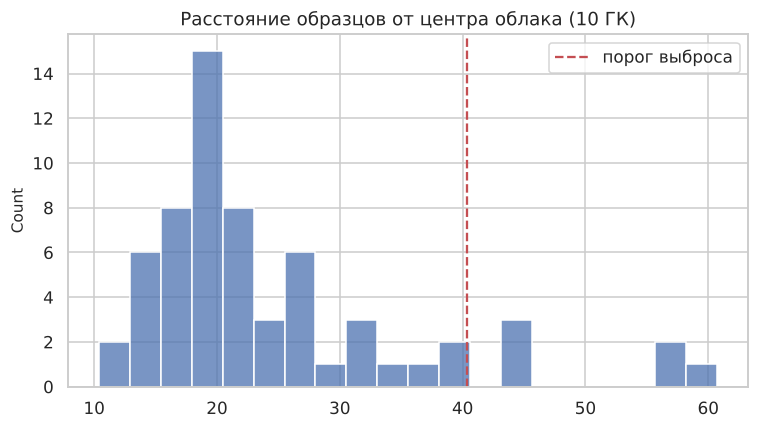

In [11]:
d_c = np.linalg.norm(Z - Z.mean(0), axis=1)
thr = np.median(d_c) + 3 * stats.median_abs_deviation(d_c, scale="normal")
out_pc = pd.Series(d_c, index=X.index).sort_values(ascending=False)
print(f"Порог выброса (медиана + 3·MAD) = {thr:.1f}")
print("Образцы с наибольшим расстоянием от центра в пространстве ГК:")
display(out_pc.head(6).round(1).to_frame("distance"))

y3 = KMeans(3, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
small = [k for k in range(3) if (y3 == k).sum() <= 3]
print("Малые кластеры при k=3 (размер ≤ 3):", {k: X.index[y3 == k].tolist() for k in small})

plt.figure(figsize=(7, 4))
sns.histplot(d_c, bins=20, color="#4c72b0")
plt.axvline(thr, c="r", ls="--", label="порог выброса"); plt.legend()
plt.title("Расстояние образцов от центра облака (10 ГК)")
plt.tight_layout()
save_fig("07_pca_outliers")
plt.show()


**Выводы:**

- Порог выброса (медиана + 3·MAD) равен **40.4**. Его превышают **GSM877186 (60.7), GSM877144 (57.7) и GSM877147 (57.6)** — те же три образца, что выделились по числу экстремальных значений (раздел 2.5). Следующие образцы (GSM877142 — 44.9, GSM877153 — 43.9) лишь немного выше порога.
- Подтверждается, что выбросы **влияют на кластеризацию**: уже при $k = 3$ K-means отщепляет в отдельный кластер пару **GSM877144 и GSM877147**, то есть третий «кластер» — это просто два выброса. Именно поэтому большие $k$ не имеют содержательного смысла (см. раздел 5.5.1).
- Выбросы сохраняются в выборке, но при интерпретации учитывается, что они могут «тянуть» центроиды K-means.


## 4. Проверка условий применимости кластеризации

| Условие | Как проверяется | 
|:---|:---|
| **Отсутствие классов** | клинические метки исключены из матрицы признаков; используются только для внешней валидации |
| **Осмысленность (кластеризуемость)** | статистика Хопкинса, матрица диаграмм рассеяния |
| **Отсутствие выбросов** | разделы 2.5 и 3.3: выбросы выявлены, сохранены, их влияние оценивается отдельно |

**Статистика Хопкинса** $H$ сравнивает расстояния до ближайшего соседа у случайных точек из равномерного распределения ($u_i$) и у выборки реальных точек ($w_i$):

$$H = \frac{\sum u_i}{\sum u_i + \sum w_i}$$

$H \approx 0.5$ — данные случайны, $H \to 1$ — выражена кластерная структура. Для калибровки сравниваем с «нулевой» моделью: те же данные, у которых каждый ген **независимо перемешан** (межобразцовая структура разрушена, а маргинальные распределения сохранены).

In [12]:
def hopkins(A, m=None, n_rep=100, seed=RANDOM_STATE):
    r = np.random.default_rng(seed)
    n, d = A.shape
    m = m or max(5, int(.2 * n))
    nn = NearestNeighbors(n_neighbors=2).fit(A)
    lo, hi = A.min(0), A.max(0)
    res = []
    for _ in range(n_rep):
        idx = r.choice(n, m, replace=False)
        w = nn.kneighbors(A[idx], 2)[0][:, 1]          # расстояние до ближайшего *другого* реального объекта
        U = r.uniform(lo, hi, (m, d))
        u = nn.kneighbors(U, 1)[0][:, 0]               # расстояние от случайной точки до ближайшего реального
        res.append(u.sum() / (u.sum() + w.sum()))
    return np.mean(res)

rp = np.random.default_rng(RANDOM_STATE)
Xperm = np.column_stack([rp.permutation(Xs[:, j]) for j in range(Xs.shape[1])])
Zperm = PCA(n_components=N_PC, random_state=RANDOM_STATE).fit_transform(Xperm)

H_real, H_perm = hopkins(Z), hopkins(Zperm)
print(f"Hopkins (реальные данные, {N_PC} ГК): {H_real:.3f}")
print(f"Hopkins (нулевая модель — гены независимо перемешаны): {H_perm:.3f}")

Hopkins (реальные данные, 10 ГК): 0.668
Hopkins (нулевая модель — гены независимо перемешаны): 0.581


**Результат:** статистика Хопкинса на реальных данных — **0.668**, на «нулевой» модели (гены независимо перемешаны) — **0.581**.

- Значение 0.668 лишь **немного превышает** уровень нулевой модели (0.581) и далеко от значений 0.8–0.9, характерных для чётко кластеризованных данных. Часть превышения над 0.5 даёт и сама нулевая модель, так что чистый «кластерный» вклад — порядка 0.09.
- Вывод: данные **кластеризуемы лишь слабо**; нельзя ожидать чётко отделённых групп. Результаты кластеризации необходимо интерпретировать осторожно и проверять на устойчивость (раздел 5.6).


### 4.1. Матрица диаграмм рассеяния

Визуальная оценка структуры в пространстве первых пяти главных компонент: предполагаемое число кластеров, их форма и плотность.

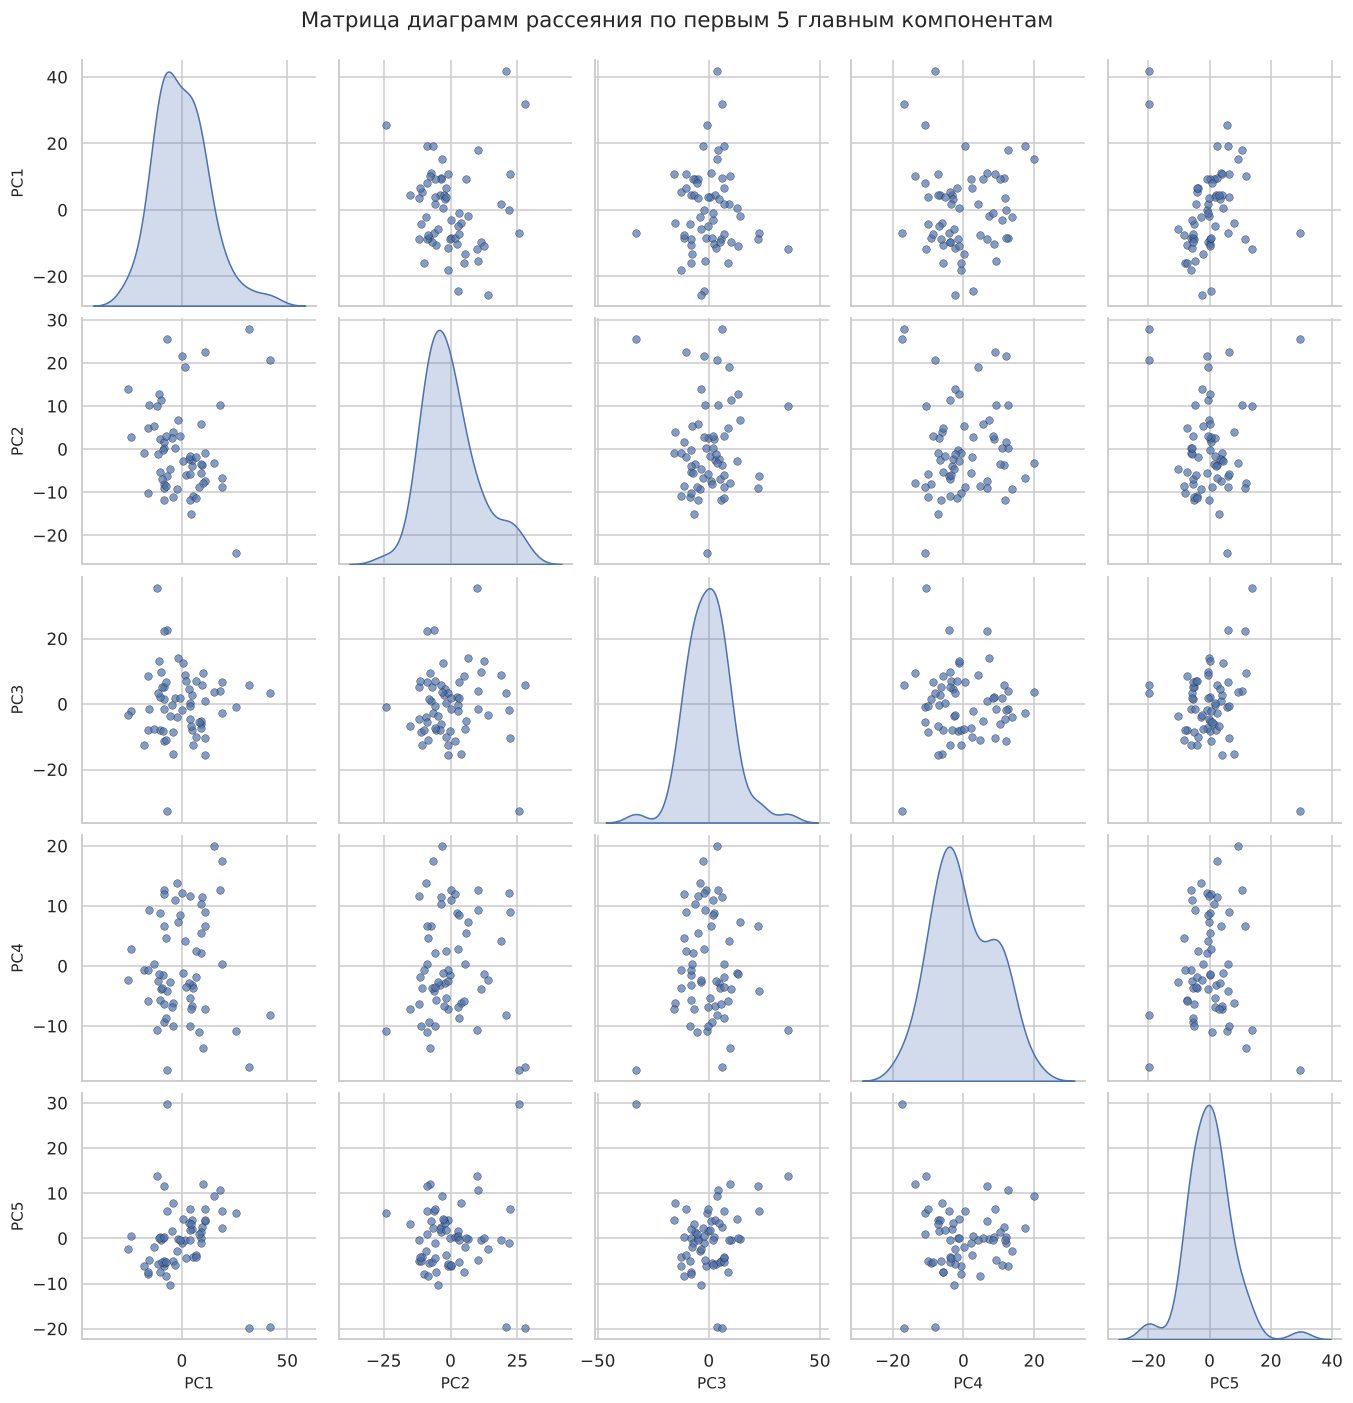

In [13]:
g = sns.pairplot(Zdf.iloc[:, :5], diag_kind="kde",
                 plot_kws=dict(s=25, alpha=.7, edgecolor="k", linewidth=.3, color="#4c72b0"))
g.fig.suptitle("Матрица диаграмм рассеяния по первым 5 главным компонентам", y=1.02, fontsize=14)
g.savefig(FIG_DIR / "08_scatter_matrix.png", bbox_inches="tight")
plt.show()


**Что видно на матрице диаграмм рассеяния:**

- Образцы образуют **единое компактное облако** без явных пустых промежутков между группами ни в одной из 10 парных проекций; на диагонали плотности одновершинные (только у PC4 заметно «плечо» справа).
- Облако вытянуто вправо/вверх: на PC1, PC2, PC3 и PC5 видны **одиночные удалённые точки** (хвосты плотностей) — это выбросы из раздела 3.3.
- **Предполагаемое число кластеров:** от 1 до 2; если разделение существует, то это два слабо перекрывающихся скопления.
- **Тип структуры:** компактная, примерно эллипсоидальная форма, умеренно различающаяся плотность (центр плотнее периферии), выбросы на периферии. Такая структура соответствует допущениям K-means и метода Уорда (компактные кластеры) и не соответствует допущениям DBSCAN (плотностные кластеры произвольной формы, разделённые разрежением).


### 4.2. Обоснование выбора методов кластеризации

| Метод | Что предполагает | Применимость к данным |
|:---|:---|:---|
| **K-means** | компактные выпуклые (шарообразные) кластеры сопоставимого размера и плотности; число кластеров задаётся | **выбран**: структура, если она есть, — слабо разделённые компактные скопления; быстрый, даёт интерпретируемые центроиды. Минус — чувствителен к выбросам и инициализации |
| **Иерархический (Уорд)** | минимизирует прирост внутрикластерной дисперсии при слиянии; не требует заранее фиксировать $k$ | **выбран**: детерминирован, даёт дендрограмму, выбросы часто сливаются последними; хорошо дополняет K-means |
| **DBSCAN** | кластеры — области высокой плотности, разделённые разреженными; шум выделяется | используется в исследовании параметров: плотность образцов неоднородна, а при $n = 62$ и 10 измерениях трудно подобрать $\varepsilon$ |
| EM / Gaussian Mixture | эллипсоидальные кластеры, ковариационные матрицы | не используется: при $n = 62$ оценка ковариаций в 10 измерениях ненадёжна |

## 5. Ход работы

### 5.1. Подбор оптимального числа кластеров

Для $k = 2 \ldots 10$ вычисляются:

- **метод локтя** — внутрикластерная сумма квадратов (`inertia`, WCSS) K-means;
- **средний силуэт** (silhouette) — для K-means и Уорда; чем ближе к 1, тем лучше;
- **индекс Calinski–Harabasz** (больше — лучше) и **Davies–Bouldin** (меньше — лучше).

Расчёт выполняется и в пространстве 10 ГК, и в полном пространстве 1935 стандартизованных генов (для сравнения).

In [14]:
K_RANGE = range(2, 11)

def eval_k(Zspace):
    rows = []
    Zl = linkage(Zspace, "ward")
    for k in K_RANGE:
        km_ = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Zspace)
        ag = fcluster(Zl, k, "maxclust")
        rows.append(dict(
            k=k, inertia=km_.inertia_,
            sil_km=silhouette_score(Zspace, km_.labels_),
            ch_km=calinski_harabasz_score(Zspace, km_.labels_),
            db_km=davies_bouldin_score(Zspace, km_.labels_),
            sil_hc=silhouette_score(Zspace, ag),
            ch_hc=calinski_harabasz_score(Zspace, ag),
            db_hc=davies_bouldin_score(Zspace, ag)))
    return pd.DataFrame(rows).set_index("k")

ev = eval_k(Z)            # пространство 10 ГК
ev_full = eval_k(Xs)      # все 1935 генов
display(ev.round(3))

,inertia,sil_km,ch_km,db_km,sil_hc,ch_hc,db_hc
k,,,,,,,
2,38056.442,0.157,10.741,2.145,0.121,9.077,2.310
3,33423.129,0.151,10.102,1.725,0.129,9.295,1.838
4,30789.326,0.139,8.841,1.804,0.131,9.147,1.424
5,28197.952,0.117,8.425,1.770,0.128,8.798,1.469
6,25871.069,0.141,8.225,1.616,0.137,8.815,1.376
7,22585.085,0.121,9.044,1.407,0.108,8.728,1.386
8,20366.875,0.139,9.281,1.339,0.114,8.709,1.297
9,19045.766,0.146,8.983,1.347,0.114,8.596,1.404
10,18056.816,0.104,8.579,1.123,0.119,8.604,1.199


Лучший k по silhouette: K-means = 2 | Ward = 6

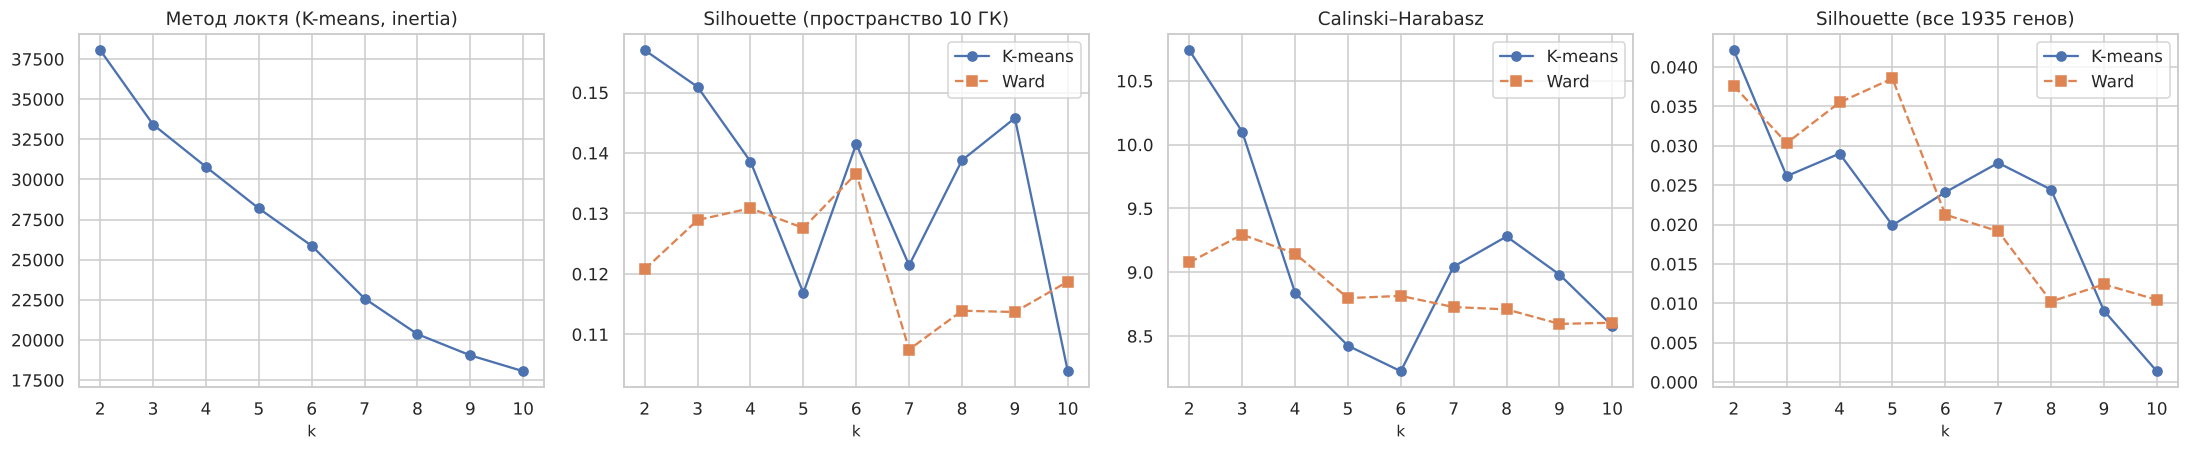

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
axes[0].plot(ev.index, ev.inertia, "o-"); axes[0].set_title("Метод локтя (K-means, inertia)")
axes[1].plot(ev.index, ev.sil_km, "o-", label="K-means")
axes[1].plot(ev.index, ev.sil_hc, "s--", label="Ward")
axes[1].set_title("Silhouette (пространство 10 ГК)"); axes[1].legend()
axes[2].plot(ev.index, ev.ch_km, "o-", label="K-means")
axes[2].plot(ev.index, ev.ch_hc, "s--", label="Ward")
axes[2].set_title("Calinski–Harabasz"); axes[2].legend()
axes[3].plot(ev_full.index, ev_full.sil_km, "o-", label="K-means")
axes[3].plot(ev_full.index, ev_full.sil_hc, "s--", label="Ward")
axes[3].set_title("Silhouette (все 1935 генов)"); axes[3].legend()
for a in axes:
    a.set_xlabel("k")
fig.tight_layout()
save_fig("09_choose_k")
plt.show()
print("Лучший k по silhouette: K-means =", ev.sil_km.idxmax(), "| Ward =", ev.sil_hc.idxmax())


**Анализ подбора $k$.**

- **Метод локтя.** Inertia монотонно и **плавно** убывает (38.1 тыс. при $k=2$ → 18.1 тыс. при $k=10$), выраженного «локтя» нет — характерно для данных без чёткой кластерной структуры.
- **Silhouette (10 ГК).** Для K-means максимум при **$k = 2$ (0.157)**, затем значения колеблются в диапазоне 0.10–0.15 без тенденции. Для Уорда силуэт почти плоский (0.108–0.137; формальный максимум **0.137 при $k = 6$**, но разница с $k=2$ (0.121) ничтожна).
- **Calinski–Harabasz** для K-means максимален при $k = 2$ (**10.7**) и далее снижается до 8.2–9.3; для Уорда почти не меняется (8.6–9.3).
- **Davies–Bouldin** монотонно «улучшается» с ростом $k$ (2.15 → 1.12), но это артефакт: растёт число кластеров из 1–2 образцов (см. раздел 5.5.1), для которых показатель занижается.
- **Полное пространство 1935 генов:** silhouette в пределах 0.01–0.04, т.е. практически ноль — расстояния в пространстве высокой размерности почти не различают образцы. Это подтверждает необходимость PCA.
- Итог: критерии не противоречат друг другу, но и не дают уверенного ответа; **$k = 2$** — наиболее обоснованный выбор (лучшие silhouette и CH у K-means; при $k \ge 3$ появляются кластеры-выбросы).


### 5.2. Иерархическая кластеризация: дендрограмма

Сначала сравним способы связи по **кофенетической корреляции** (насколько дендрограмма сохраняет исходные попарные расстояния), затем построим дендрограмму метода Уорда.

Кофенетическая корреляция:
Последние 8 слияний (высоты): [ 55.6  61.8  65.2  72.6  73.7  85.6  98.5 108.6]

,cophenetic
linkage,
ward,0.394
average,0.885
complete,0.793
single,0.863


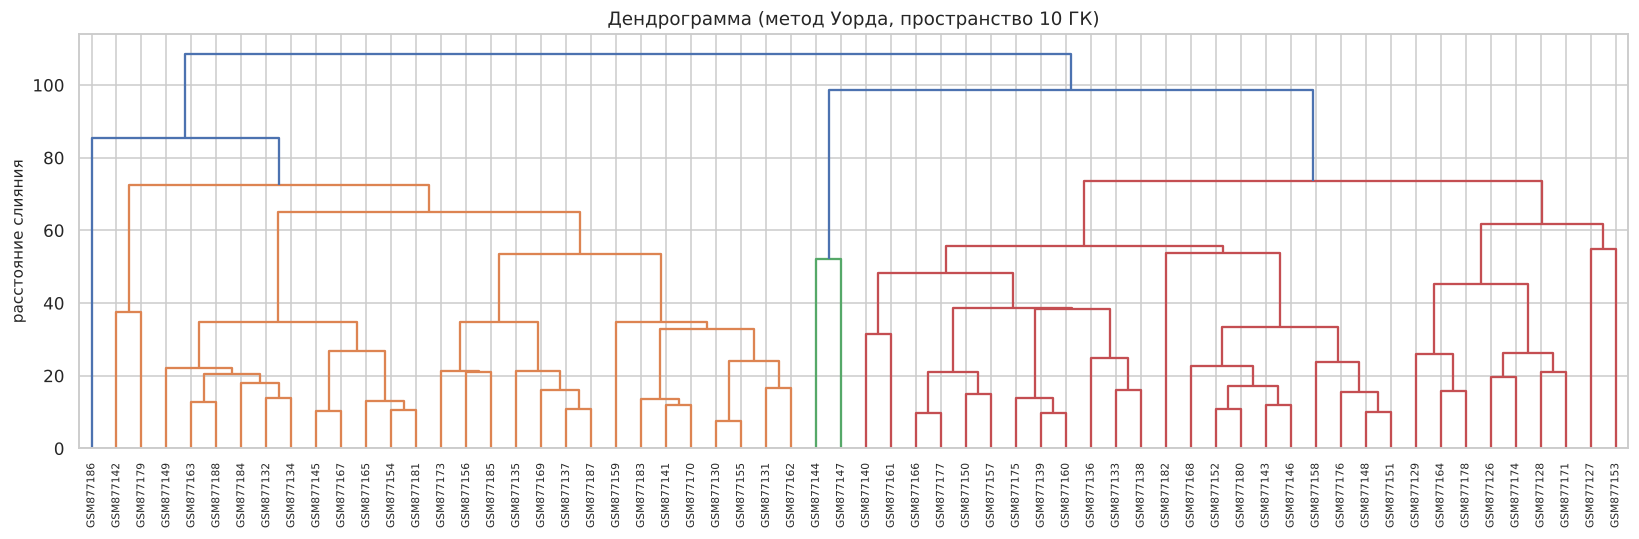

In [16]:
rows = []
for m_ in ["ward", "average", "complete", "single"]:
    Lm = linkage(Z, m_)
    rows.append((m_, cophenet(Lm, pdist(Z))[0]))
print("Кофенетическая корреляция:")
display(pd.DataFrame(rows, columns=["linkage", "cophenetic"]).set_index("linkage").round(3))

L = linkage(Z, "ward")
plt.figure(figsize=(15, 5))
dendrogram(L, labels=X.index.tolist(), leaf_rotation=90, leaf_font_size=7, color_threshold=0.7 * L[-1, 2])
plt.title("Дендрограмма (метод Уорда, пространство 10 ГК)")
plt.ylabel("расстояние слияния")
plt.tight_layout()
save_fig("10_dendrogram")
plt.show()
print("Последние 8 слияний (высоты):", np.round(L[-8:, 2], 1))


**Анализ дендрограммы.**

- Кофенетическая корреляция метода Уорда (0.394) ниже, чем у average (0.885), single (0.863) и complete (0.793). Эти значения нельзя напрямую сравнивать: Уорд минимизирует прирост дисперсии, и его высоты слияния измеряются в других единицах; для average/single/complete сохранение исходных расстояний — прямая цель метода. Метод Уорда выбран за **компактность** получаемых кластеров, а single-связь для этих данных непригодна (эффект «цепочки», выбросы дают одиночные кластеры).
- На дендрограмме самое высокое слияние происходит на высоте **108.6**, следующее — **98.5**, затем 85.6 и 73.7. Скачка, резко отделяющего «2 кластера» от «3 кластеров», нет: высоты убывают плавно.
- **Отдельные ветви выбросов видны явно:** образец **GSM877186** присоединяется к левой ветви на большой высоте (≈ 85) практически как одиночный объект, а пара **GSM877144 + GSM877147** образует отдельную зелёную ветвь, которая присоединяется к правой группе лишь на высоте ≈ 98. Это согласуется с выводами о выбросах.
- Срез на двух кластерах делит выборку на левую (оранжевую) группу и правую (красную + зелёная) группу; средний уровень внутри групп — слияния на высотах 20–70, то есть группы довольно «рыхлые».


### 5.3. Итоговая кластеризация двумя методами

Параметры выбраны по результатам раздела 5.1:

| Метод | Параметры |
|:---|:---|
| **K-means** | `n_clusters = 2`, `n_init = 10` (10 случайных инициализаций, берётся лучшая по inertia), `random_state = 42`, пространство 10 ГК |
| **Иерархический** | `linkage = ward`, евклидова метрика, срез дендрограммы на 2 кластера, пространство 10 ГК |

In [17]:
K = 2
km = KMeans(K, n_init=10, random_state=RANDOM_STATE).fit(Z)
lab_km = km.labels_
lab_hc = fcluster(L, K, "maxclust") - 1

print("Размеры кластеров  K-means:", np.bincount(lab_km), "| Ward:", np.bincount(lab_hc))
print("\nТаблица сопряжённости методов:")
display(pd.crosstab(lab_km, lab_hc, rownames=["K-means"], colnames=["Ward"]))

Размеры кластеров  K-means: [36 26] | Ward: [29 33]

Таблица сопряжённости методов:

Ward,0,1
K-means,,
0,29,7
1,0,26



**Итоговое разбиение ($k = 2$).**

- **K-means:** кластеры 36 и 26 образцов; **Ward:** 29 и 33 образца.
- Таблица сопряжённости показывает, что методы согласуются по «ядру» групп: **все 26 образцов кластера 1 K-means попали в кластер 1 метода Уорда**; кластер 0 K-means (36 образцов) методом Уорда разделён на 29 + 7 — 7 «пограничных» образцов Уорд отнёс к другому кластеру. Расхождение сосредоточено на границе между группами — типично для слабо разделённой структуры.


### 5.4. Метрики качества

#### 5.4.1. Внутренние метрики

| Метрика | Формула / смысл | Лучшее значение |
|:---|:---|:---|
| **Silhouette** | $s_i = \dfrac{b_i - a_i}{\max(a_i, b_i)}$, где $a_i$ — среднее расстояние до своего кластера, $b_i$ — до ближайшего чужого | → 1 |
| **Calinski–Harabasz** | $\dfrac{SS_B/(k-1)}{SS_W/(n-k)}$ — отношение межкластерной и внутрикластерной дисперсии | больше |
| **Davies–Bouldin** | среднее по кластерам $\max_{j\ne i}\dfrac{s_i + s_j}{d_{ij}}$ — «похожесть» кластера на ближайший | меньше |
| **Dunn** | $\dfrac{\min \text{ межкластерное расстояние}}{\max \text{ диаметр кластера}}$ | больше |
| **WCSS** | $\sum_k \sum_{x\in C_k}\lVert x - \mu_k\rVert^2$ — внутрикластерная сумма квадратов (компактность) | меньше |
| **Ср. внутрикластерное расстояние** | среднее попарное расстояние внутри кластеров | меньше |
| **Расстояние между центроидами** | среднее попарное расстояние между центрами кластеров | больше |
| **Мин. расстояние между кластерами** | расстояние между ближайшими точками разных кластеров | больше |

In [18]:
def internal_metrics(A_, y):
    ks = np.unique(y)
    cents = np.array([A_[y == k].mean(0) for k in ks])
    intra = [pdist(A_[y == k]).mean() if (y == k).sum() > 1 else 0 for k in ks]
    diam = [pdist(A_[y == k]).max() if (y == k).sum() > 1 else 0 for k in ks]
    wcss = sum(((A_[y == k] - cents[i]) ** 2).sum() for i, k in enumerate(ks))
    inter_min = min(cdist(A_[y == a], A_[y == b]).min() for i, a in enumerate(ks) for b in ks[i + 1:])
    return {"Silhouette": silhouette_score(A_, y),
            "Calinski–Harabasz": calinski_harabasz_score(A_, y),
            "Davies–Bouldin": davies_bouldin_score(A_, y),
            "Dunn": inter_min / max(diam),
            "WCSS": wcss,
            "Ср. внутрикласт. расстояние": np.mean(intra),
            "Ср. расстояние между центроидами": pdist(cents).mean(),
            "Мин. расстояние между кластерами": inter_min}

tab_int = pd.DataFrame({"K-means": internal_metrics(Z, lab_km), "Ward": internal_metrics(Z, lab_hc)})
display(tab_int.round(3))

tab_int_full = pd.DataFrame({"K-means": internal_metrics(Xs, lab_km), "Ward": internal_metrics(Xs, lab_hc)})
print("Те же разбиения, метрики в исходном стандартизованном пространстве (1935 генов):")
display(tab_int_full.loc[["Silhouette", "Calinski–Harabasz", "Davies–Bouldin"]].round(3))

print("Согласованность двух методов: ARI = %.3f, NMI = %.3f"
      % (adjusted_rand_score(lab_km, lab_hc), normalized_mutual_info_score(lab_km, lab_hc)))

Те же разбиения, метрики в исходном стандартизованном пространстве (1935 генов):
Согласованность двух методов: ARI = 0.593, NMI = 0.591

,K-means,Ward
Silhouette,0.157,0.121
Calinski–Harabasz,10.741,9.077
Davies–Bouldin,2.145,2.310
Dunn,0.132,0.174
WCSS,38056.442,38973.018
Ср. внутрикласт. расстояние,33.387,33.128
Ср. расстояние между центроидами,21.243,19.544
Мин. расстояние между кластерами,10.129,13.376


,K-means,Ward
Silhouette,0.046,0.033
Calinski–Harabasz,3.790,3.343
Davies–Bouldin,3.912,4.183



**Интерпретация внутренних метрик (пространство 10 ГК).**

| Метрика | K-means | Ward | Лучше |
|:---|---:|---:|:---|
| Silhouette | 0.157 | 0.121 | K-means |
| Calinski–Harabasz | 10.74 | 9.08 | K-means |
| Davies–Bouldin | 2.15 | 2.31 | K-means |
| Dunn | 0.132 | 0.174 | Ward |
| WCSS | 38 056 | 38 973 | K-means (на 2.3 %) |
| Ср. внутрикластерное расстояние | 33.4 | 33.1 | ≈ равны |
| Ср. расстояние между центроидами | 21.2 | 19.5 | K-means |
| Мин. расстояние между кластерами | 10.1 | 13.4 | Ward |

- **Silhouette 0.157 и 0.121** положительны, но очень малы: по общепринятой шкале значения ниже ~0.25 означают **слабую структуру**. В полном пространстве 1935 генов те же разбиения дают silhouette лишь **0.046 (K-means) и 0.033 (Ward)** — почти ноль.
- **Davies–Bouldin ≈ 2.1–2.3** (хорошее разделение — значения < 1): кластеры существенно перекрываются.
- **Компактность и разделённость.** Среднее внутрикластерное расстояние (**≈ 33**) в 1.5–1.7 раза превышает среднее расстояние между центроидами (**≈ 20**): кластеры «толще», чем расстояние между их центрами. Это количественно подтверждает вывод матрицы диаграмм об отсутствии чёткого разделения.
- K-means лучше по метрикам, использующим дисперсии (Silhouette, CH, DB, WCSS) — естественно, ведь он оптимизирует именно WCSS. Метод Уорда выигрывает по Dunn (0.174 против 0.132) и минимальному расстоянию между кластерами (13.4 против 10.1): иерархическое разбиение оставляет больше зазор между ближайшими объектами разных кластеров. Dunn очень чувствителен к единичным точкам, поэтому ему доверяем меньше.
- **Центры кластеров** детально рассмотрены в разделе 6.2.
- **Согласованность методов:** ARI = **0.593**, NMI = **0.591** — умеренная: общее ядро групп есть, а граница проходит по-разному.


Доля образцов с отрицательным silhouette: K-means = 8.1%, Ward = 11.3%

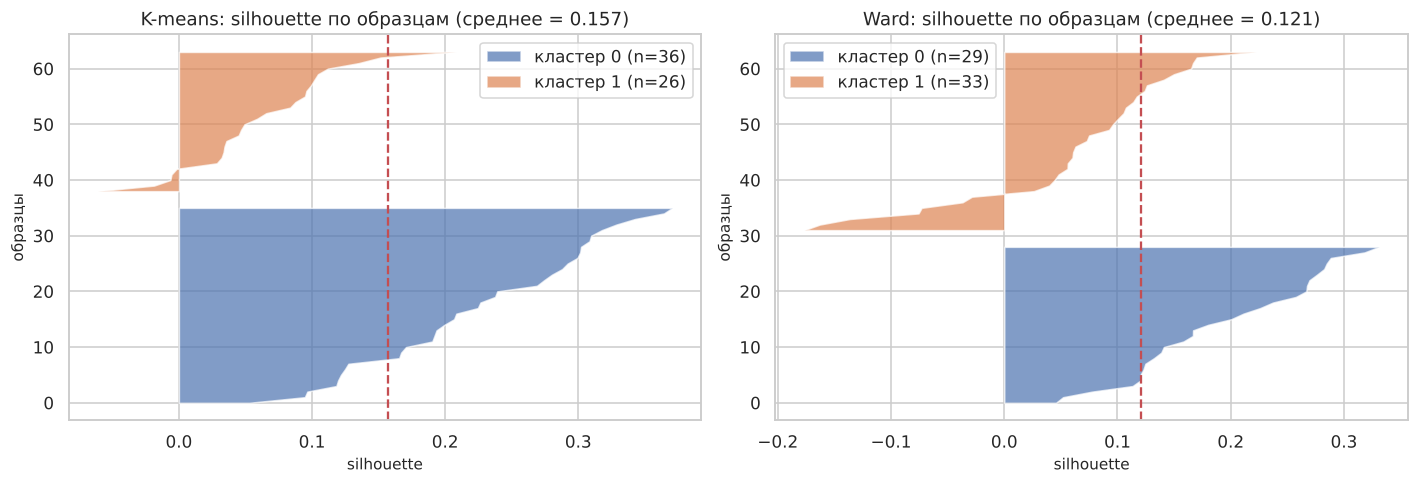

In [19]:
sil_km_s = silhouette_samples(Z, lab_km)
sil_hc_s = silhouette_samples(Z, lab_hc)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, y, s) in zip(axes, [("K-means", lab_km, sil_km_s), ("Ward", lab_hc, sil_hc_s)]):
    yl = 0
    for k in np.unique(y):
        sk = np.sort(s[y == k])
        ax.fill_betweenx(np.arange(yl, yl + len(sk)), 0, sk, alpha=.7, label=f"кластер {k} (n={len(sk)})")
        yl += len(sk) + 2
    ax.axvline(s.mean(), c="r", ls="--")
    ax.set_title(f"{name}: silhouette по образцам (среднее = {s.mean():.3f})")
    ax.set_xlabel("silhouette"); ax.set_ylabel("образцы"); ax.legend()
fig.tight_layout()
save_fig("11_silhouette_samples")
plt.show()
print("Доля образцов с отрицательным silhouette: K-means = %.1f%%, Ward = %.1f%%"
      % ((sil_km_s < 0).mean() * 100, (sil_hc_s < 0).mean() * 100))


**Silhouette по образцам.** Средние значения совпадают с таблицей (0.157 у K-means, 0.121 у Уорда), но профили кластеров очень разные:

- **K-means:** кластер 0 (36 образцов) — «хороший»: все силуэты положительны, у верхней трети они достигают 0.3–0.37. Кластер 1 (26 образцов) — слабый: у большинства образцов силуэт < 0.2, а у нескольких (около 4–5) он отрицателен.
- **Ward:** кластер 0 (29 образцов) компактен (силуэт до 0.33), а в кластере 1 (33 образца) около **7 образцов имеют отрицательный силуэт вплоть до −0.17** — это те самые пограничные образцы, которые K-means отнёс к другому кластеру (таблица сопряжённости, раздел 5.3). Они «натянуты» на кластер, которому на самом деле не принадлежат.
- Доля образцов с отрицательным силуэтом — **8.1 % у K-means и 11.3 % у Уорда**; это количественно объясняет более низкое среднее значение у метода Уорда.


#### 5.4.2. Внешние метрики

Внешние метрики сравнивают найденное разбиение с известными клиническими группами. Для пар объектов (одинаково ли они сгруппированы в разбиении и в эталоне):

| Метрика | Смысл |
|:---|:---|
| **ARI** (Adjusted Rand Index) | доля согласованных пар, скорректированная на случайность: 1 — полное совпадение, ≈ 0 — случайное |
| **NMI** | нормированная взаимная информация между разбиениями |
| **Индекс Жаккара** | $\dfrac{TP}{TP + FP + FN}$ по парам объектов |
| **Fowlkes–Mallows** | $\sqrt{\dfrac{TP}{TP+FP}\cdot\dfrac{TP}{TP+FN}}$ |
| **Homogeneity / Completeness** | каждый кластер содержит объекты одного класса / все объекты класса попали в один кластер |

Эталоном служат клинические признаки (стадия Дьюка, пол, локализация, событие рецидива, терапия). Это **необязательная** проверка: молекулярные кластеры не обязаны совпадать с клиническими группами.

In [20]:
def external_metrics(y, t):
    (tn, fp), (fn, tp) = pair_confusion_matrix(t, y)
    return {"ARI": adjusted_rand_score(t, y),
            "NMI": normalized_mutual_info_score(t, y),
            "Jaccard (по парам)": tp / (tp + fp + fn),
            "Fowlkes–Mallows": fowlkes_mallows_score(t, y),
            "Homogeneity": homogeneity_score(t, y),
            "Completeness": completeness_score(t, y)}

ext = {}
for c in ["Dukes Stage", "Gender", "Location", "DFS event", "Adj_Radio", "Adj_Chem"]:
    for name, y in [("K-means", lab_km), ("Ward", lab_hc)]:
        ext[(c, name)] = external_metrics(y, meta[c].values)
ext = pd.DataFrame(ext).T
ext.index.names = ["Признак", "Метод"]
display(ext.round(3))

ARI    NMI  Jaccard (по парам)  Fowlkes–Mallows  Homogeneity  Completeness
Признак     Метод                                                                                
Dukes Stage K-means -0.006  0.014               0.196            0.349        0.011         0.022
            Ward    -0.023  0.003               0.186            0.333        0.002         0.004
Gender      K-means -0.010  0.000               0.391            0.566        0.000         0.000
            Ward    -0.013  0.001               0.383            0.559        0.002         0.001
Location    K-means  0.006  0.048               0.237            0.395        0.038         0.067
            Ward    -0.021  0.023               0.222            0.374        0.018         0.031
DFS event   K-means -0.017  0.001               0.333            0.500        0.001         0.001
            Ward    -0.015  0.000               0.329            0.495        0.000         0.000
Adj_Radio   K-means -0.016  0.000               0.326            0.491        0.000         0.000
            Ward    -0.007  0.006               0.325            0.490        0.006         0.006
Adj_Chem    K-means -0.007  0.008               0.329            0.495        0.008         0.008
            Ward    -0.012  0.003               0.322            0.487        0.003         0.003


**Интерпретация внешних метрик.**

- **ARI от −0.023 до +0.006**, **NMI ≤ 0.048**, **Homogeneity и Completeness ≤ 0.067** по всем шести клиническим признакам и обоим методам: найденные кластеры **не соответствуют** стадии Дьюка, полу, локализации, факту рецидива и терапии. Значения ARI около нуля означают, что совпадение хуже или равно случайному.
- **Индекс Жаккара (0.19–0.39) и Fowlkes–Mallows (0.33–0.57)** выглядят «заметными», но это иллюзия: они не скорректированы на случайность и зависят от размеров групп. Например, для пола Жаккар 0.39 получается просто потому, что 77 % образцов — мужчины, и любое случайное разбиение «объединит» много пар мужчин. Скорректированный ARI в этом же случае равен −0.010.
- Самые высокие (всё равно очень низкие) NMI/Homogeneity — по локализации опухоли у K-means (NMI = 0.048, Homogeneity = 0.038); различия в пределах шума.
- Итог: доминирующая вариация экспрессии в этом наборе **не связана** с изученными клиническими категориями. Это не ошибка метода — молекулярные группы не обязаны совпадать с клинической стадией; возможно, они отражают другие факторы (состав ткани, батч-эффекты, молекулярные подтипы, не отражённые в доступных метках).


### 5.5. Влияние параметров на качество кластеризации

#### 5.5.1. K-means: число кластеров $k$

,Silhouette,CH,DB,min_size,ARI_Dukes
k,,,,,
2,0.157,10.741,2.145,26,-0.006
3,0.151,10.102,1.725,2,-0.004
4,0.139,8.841,1.804,2,-0.009
5,0.117,8.425,1.770,2,0.002
6,0.141,8.225,1.616,2,-0.011
7,0.121,9.044,1.407,1,-0.016
8,0.139,9.281,1.339,1,-0.026
9,0.146,8.983,1.347,1,-0.005
10,0.104,8.579,1.123,1,0.008


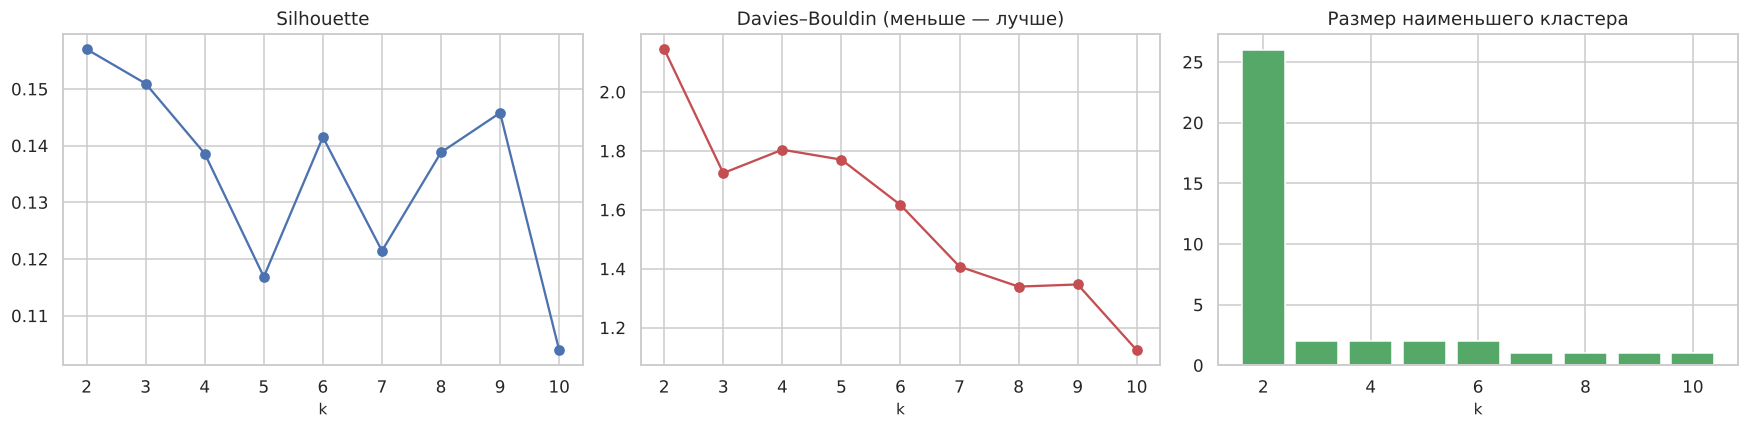

In [21]:
rows = []
for k in K_RANGE:
    y = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
    rows.append(dict(k=k, Silhouette=silhouette_score(Z, y), CH=calinski_harabasz_score(Z, y),
                     DB=davies_bouldin_score(Z, y), min_size=np.bincount(y).min(),
                     ARI_Dukes=adjusted_rand_score(meta["Dukes Stage"], y)))
pk = pd.DataFrame(rows).set_index("k")
display(pk.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(pk.index, pk.Silhouette, "o-"); axes[0].set_title("Silhouette")
axes[1].plot(pk.index, pk.DB, "o-", c="#c44e52"); axes[1].set_title("Davies–Bouldin (меньше — лучше)")
axes[2].bar(pk.index, pk.min_size, color="#55a868"); axes[2].set_title("Размер наименьшего кластера")
for a in axes:
    a.set_xlabel("k")
fig.tight_layout()
save_fig("12_param_k")
plt.show()


**Влияние $k$ на качество K-means.**

- **Silhouette** максимален при $k = 2$ (**0.157**), при $k = 3$ почти не падает (0.151), затем колеблется между 0.10 и 0.15 без устойчивого тренда. **Calinski–Harabasz** падает с 10.7 ($k=2$) до 8.2–9.3.
- **Davies–Bouldin** «улучшается» с 2.15 до 1.12 при росте $k$, но колонка `min_size` показывает причину: **начиная с $k = 3$ наименьший кластер состоит из 1–2 образцов** — выбросов. DB занижается для таких вырожденных кластеров, поэтому его улучшение не означает лучшей структуры.
- Единственное значение $k$, при котором все кластеры содержательны (наименьший — 26 образцов) — **$k = 2$**.
- **ARI относительно стадии Дьюка** не зависит от $k$ и остаётся около нуля (от −0.026 до +0.008): увеличение числа кластеров не приближает разбиение к клинической классификации.


#### 5.5.2. DBSCAN: параметры $\varepsilon$ и `min_samples`

Радиус окрестности $\varepsilon$ подбираем по графику k-расстояний (k-distance plot): «колено» кривой отсортированных расстояний до 4-го соседа. Затем строим сетку $\varepsilon \times$ `min_samples` и смотрим число кластеров, долю шума и silhouette (без шумовых точек).

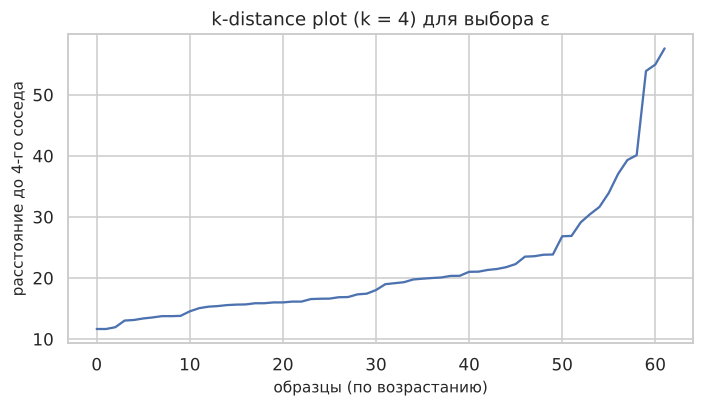

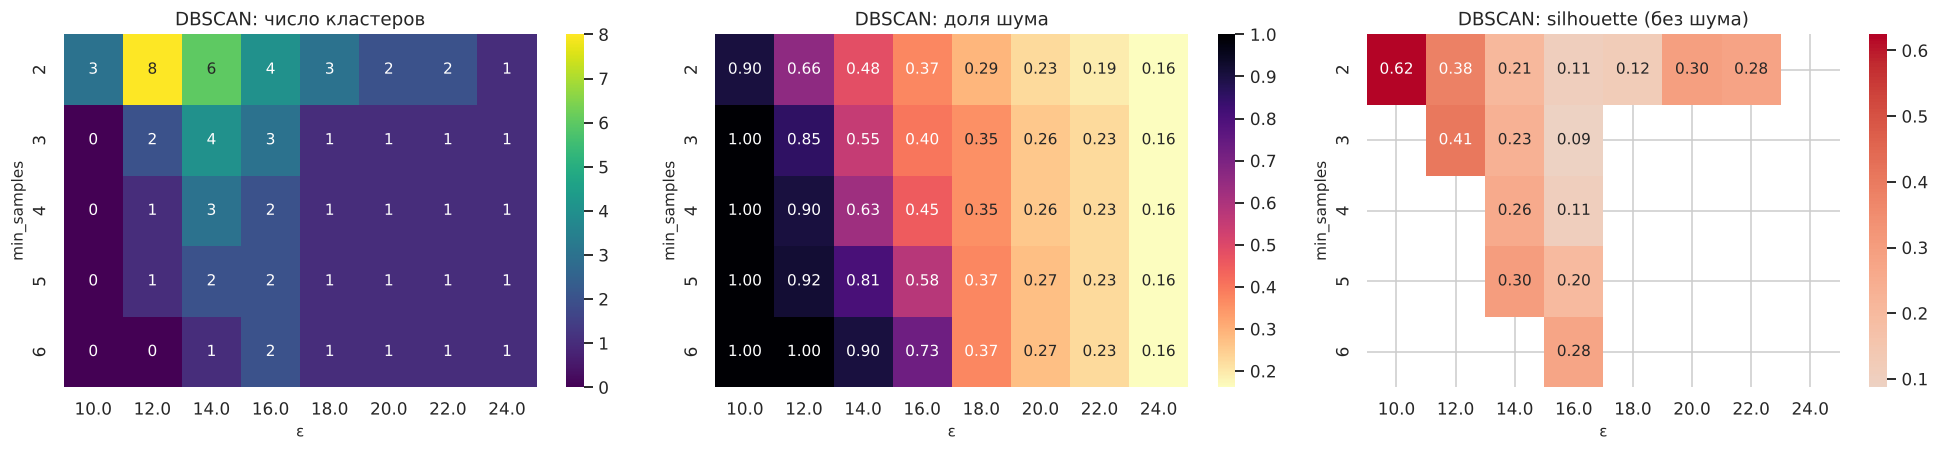

In [22]:
nbr = NearestNeighbors(n_neighbors=4).fit(Z)
kd = np.sort(nbr.kneighbors(Z)[0][:, -1])
plt.figure(figsize=(6.5, 3.8))
plt.plot(kd)
plt.title("k-distance plot (k = 4) для выбора ε")
plt.ylabel("расстояние до 4-го соседа"); plt.xlabel("образцы (по возрастанию)")
plt.tight_layout()
save_fig("13_kdistance")
plt.show()

eps_grid = np.round(np.linspace(10, 24, 8), 1)
ms_grid = [2, 3, 4, 5, 6]
ncl = pd.DataFrame(index=ms_grid, columns=eps_grid, dtype=float)
noise = ncl.copy(); sil = ncl.copy()
for e in eps_grid:
    for m_ in ms_grid:
        y = DBSCAN(eps=e, min_samples=m_).fit_predict(Z)
        mask = y != -1
        ncl.loc[m_, e] = len(set(y)) - (1 if -1 in y else 0)
        noise.loc[m_, e] = 1 - mask.mean()
        sil.loc[m_, e] = silhouette_score(Z[mask], y[mask]) if ncl.loc[m_, e] >= 2 else np.nan

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
sns.heatmap(ncl, annot=True, fmt=".0f", cmap="viridis", ax=axes[0]); axes[0].set_title("DBSCAN: число кластеров")
sns.heatmap(noise, annot=True, fmt=".2f", cmap="magma_r", ax=axes[1]); axes[1].set_title("DBSCAN: доля шума")
sns.heatmap(sil, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[2]); axes[2].set_title("DBSCAN: silhouette (без шума)")
for a in axes:
    a.set_xlabel("ε"); a.set_ylabel("min_samples")
fig.tight_layout()
save_fig("14_dbscan_grid")
plt.show()


**k-distance plot.** Кривая отсортированных расстояний до 4-го соседа плавно растёт от ≈ 12 до ≈ 40 и затем резко взлетает до **≈ 54–58** для трёх последних точек (это выбросы); чёткого «колена», по которому можно выбрать $\varepsilon$, в основной части кривой нет — ещё одно свидетельство отсутствия плотностных кластеров. Сетка перебирает $\varepsilon$ от 10 до 24.

**Влияние параметров DBSCAN:**

- **$\varepsilon \le 10$:** почти все образцы — шум (при `min_samples ≥ 3` шум = 100 %, кластеров нет); при `min_samples = 2` — 3 кластера из очень близких пар, но 90 % образцов в шуме.
- **$\varepsilon = 12$–$16$:** образуются от 1 до 8 мелких кластеров (по 2–5 образцов), но доля шума остаётся **от 37 до 100 %**. Silhouette «без шума» нередко высок (до 0.41 при $\varepsilon=12$) — это артефакт: оценивается только горстка плотных пар образцов, а большинство объектов в расчёт не входит.
- **$\varepsilon \ge 18$:** остаётся **1 кластер** (для `min_samples ≥ 3`) и доля шума 16–37 %: единое ядро и выбросы по периферии. Два кластера при $\varepsilon = 20$–$22$ и `min_samples = 2` — это «ядро» плюс небольшая группа образцов (доля шума 19–23 %).
- Увеличение `min_samples` при фиксированном $\varepsilon$ **сокращает число кластеров и увеличивает шум**; увеличение $\varepsilon$ — наоборот. Ни одна комбинация не даёт 2+ содержательных кластеров с малой долей шума.

**Вывод:** DBSCAN не обнаруживает плотностных кластеров и очень чувствителен к параметрам; он полезен здесь лишь как **детектор выбросов** (три образца с расстоянием 54–58 всегда остаются шумом). Для данной задачи он неприменим как основной метод.


### 5.6. Устойчивость кластеров

Устойчивость оцениваем **бутстреп-подвыборками**: 100 раз берём случайные 80 % образцов, кластеризуем и сравниваем (ARI) полученные метки с метками полной выборки для тех же образцов. ARI ≈ 1 — разбиение воспроизводится; ARI ≈ 0 — нестабильно. Отдельно проверяем зависимость K-means от инициализации (`n_init = 1`, 30 запусков).

K-means, n_init=1, 30 запусков: средний попарный ARI = 0.236

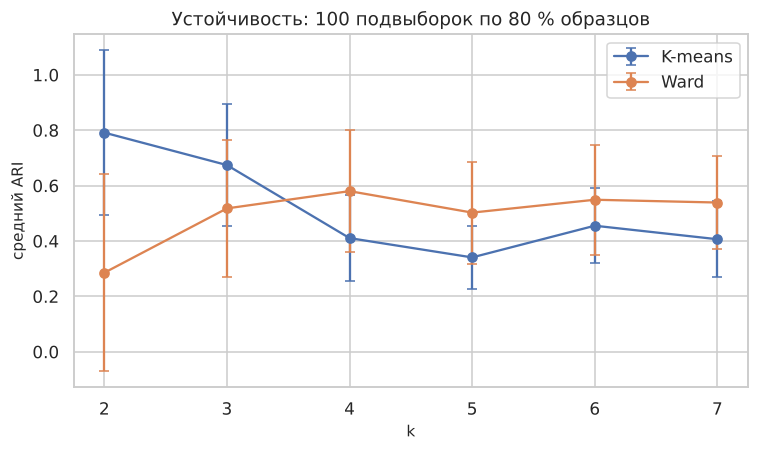

,2,3,4,5,6,7
K-means,0.791,0.674,0.411,0.341,0.455,0.406
Ward,0.285,0.518,0.580,0.503,0.549,0.539


In [23]:
def stability(k, n_rep=100, frac=.8):
    r = np.random.default_rng(RANDOM_STATE)
    n = len(Z)
    out = {"K-means": [], "Ward": []}
    full_km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
    full_hc = fcluster(linkage(Z, "ward"), k, "maxclust")
    for _ in range(n_rep):
        idx = r.choice(n, int(frac * n), replace=False)
        out["K-means"].append(adjusted_rand_score(
            full_km[idx], KMeans(k, n_init=10, random_state=int(r.integers(1e6))).fit_predict(Z[idx])))
        out["Ward"].append(adjusted_rand_score(
            full_hc[idx], fcluster(linkage(Z[idx], "ward"), k, "maxclust")))
    return {m_: (np.mean(v), np.std(v)) for m_, v in out.items()}

stab = {k: stability(k) for k in range(2, 8)}
st = pd.DataFrame({m_: [stab[k][m_][0] for k in stab] for m_ in ["K-means", "Ward"]}, index=list(stab))
st_sd = pd.DataFrame({m_: [stab[k][m_][1] for k in stab] for m_ in ["K-means", "Ward"]}, index=list(stab))

plt.figure(figsize=(7, 4.2))
for m_ in st:
    plt.errorbar(st.index, st[m_], yerr=st_sd[m_], marker="o", capsize=3, label=m_)
plt.xlabel("k"); plt.ylabel("средний ARI"); plt.legend()
plt.title("Устойчивость: 100 подвыборок по 80 % образцов")
plt.tight_layout()
save_fig("15_stability")
plt.show()
display(st.round(3).T)

seed_labels = [KMeans(K, n_init=1, random_state=s).fit_predict(Z) for s in range(30)]
mean_ari_seeds = np.mean([adjusted_rand_score(seed_labels[i], seed_labels[j])
                          for i in range(30) for j in range(i + 1, 30)])
print("K-means, n_init=1, 30 запусков: средний попарный ARI = %.3f" % mean_ari_seeds)


**Результаты устойчивости (средний ARI по 100 подвыборкам).**

| $k$ | 2 | 3 | 4 | 5 | 6 | 7 |
|:---|---:|---:|---:|---:|---:|---:|
| K-means | **0.791** | 0.674 | 0.411 | 0.341 | 0.455 | 0.406 |
| Ward | 0.285 | 0.518 | 0.580 | 0.503 | 0.549 | 0.539 |

- **K-means при $k = 2$ устойчив** (ARI = 0.79): разбиение на 36 + 26 воспроизводится при удалении 20 % образцов. Разбиение на 3 группы — менее устойчиво (0.67), на 4–7 групп — ARI падает до 0.34–0.46.
- **Ward при $k = 2$ неустойчив** (ARI = 0.29): граница между двумя кластерами определяется несколькими пограничными образцами (см. таблицу сопряжённости), и при исключении части образцов дерево «перестраивается». При $k = 4$–$7$ его устойчивость (0.50–0.58) выше, чем у K-means, но эти разбиения содержат кластеры-выбросы.
- **Зависимость K-means от инициализации:** при `n_init = 1` средний попарный ARI между 30 запусками составляет всего **0.236** — результат сильно зависит от случайного старта. Именно поэтому необходимо использовать `n_init = 10` (и более), как рекомендовано в задании: лучший из 10 запусков по inertia воспроизводим.
- Общий вывод: даже самое устойчивое разбиение ($k = 2$, K-means) — лишь умеренно надёжное; разбиения с $k \ge 4$ почти полностью нестабильны. Это согласуется с выводом о слабой кластерной структуре.


## 6. Визуализация результатов

### 6.1. Диаграммы рассеяния с выделенными кластерами

Образцы проецируются на первые две главные компоненты. Для сравнения справа показана истинная стадия Дьюка.

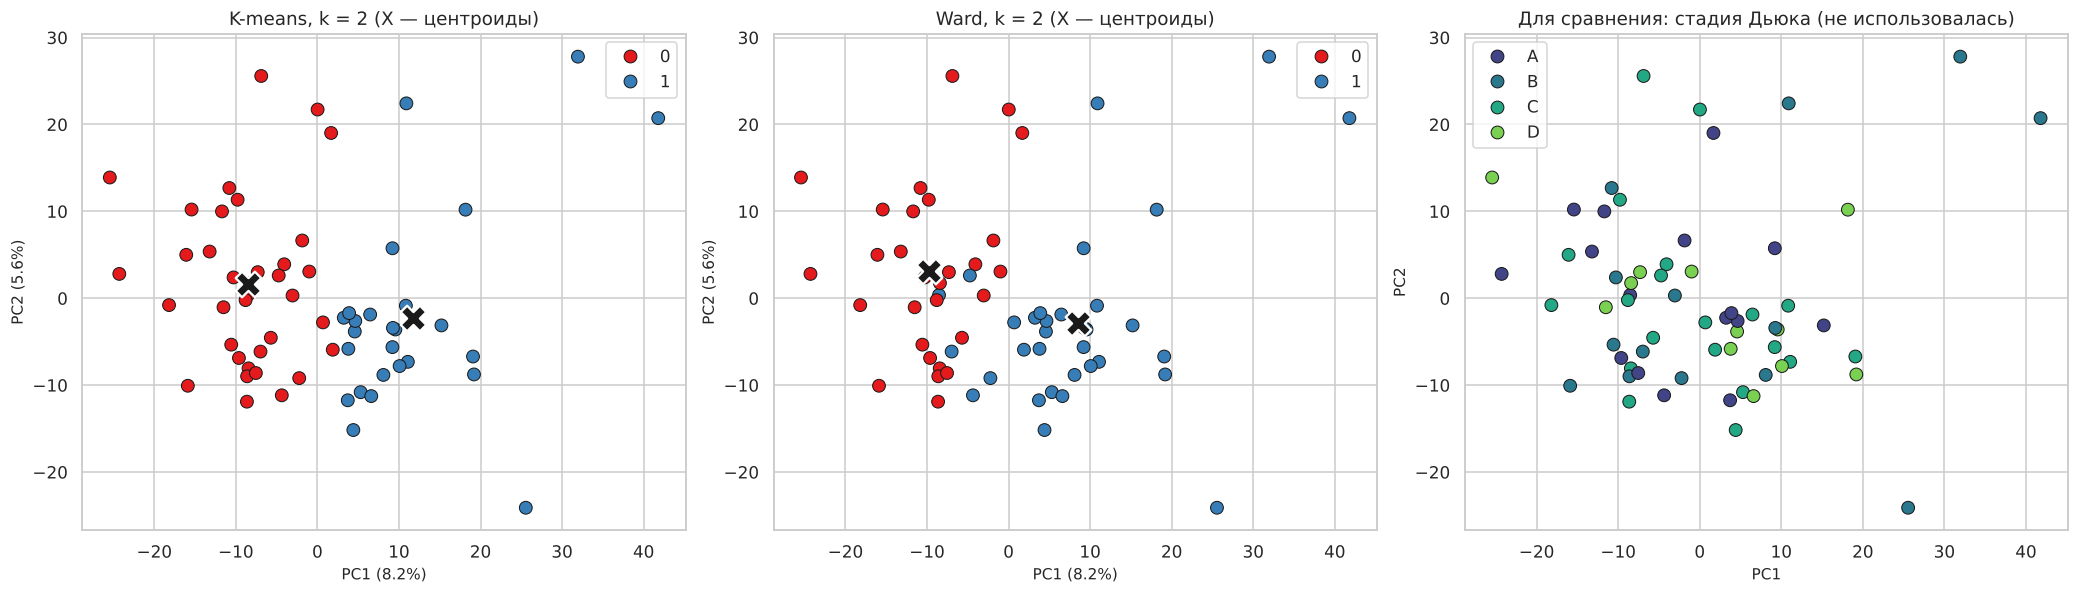

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, (name, y) in zip(axes[:2], [("K-means", lab_km), ("Ward", lab_hc)]):
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y, palette="Set1", s=70, edgecolor="k", ax=ax)
    for k in np.unique(y):
        ax.scatter(*Z[y == k][:, :2].mean(0), marker="X", s=280, c="k", edgecolor="w", linewidth=1.5)
    ax.set_title(f"{name}, k = {K} (X — центроиды)")
    ax.set_xlabel(f"PC1 ({evr[0]:.1%})"); ax.set_ylabel(f"PC2 ({evr[1]:.1%})")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=meta["Dukes Stage"].values, hue_order=list("ABCD"),
                palette="viridis", s=70, edgecolor="k", ax=axes[2])
axes[2].set_title("Для сравнения: стадия Дьюка (не использовалась)")
axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2")
fig.tight_layout()
save_fig("16_clusters_pca")
plt.show()


**Анализ диаграмм рассеяния.**

- Оба метода делят единое облако **главным образом вдоль PC1**: кластер 0 — левая, более рассеянная часть (отрицательные значения PC1), кластер 1 — правая часть, где образцы плотнее; на плоскости PC1–PC2 кластеры **перекрываются** около нуля PC1 и не разделены зоной разрежения. Центроиды (чёрные X) лежат внутри облака, а не на отдельных «островах».
- Метод Уорда (29 + 33) смещает границу влево относительно K-means (36 + 26): 7 образцов, которые K-means относит к кластеру 0, Уорд относит к кластеру 1 (раздел 5.3). Именно они имеют отрицательный силуэт на графике раздела 5.4.1.
- Три удалённых образца-выброса (правая часть графика: PC1 ≈ 25–42) попадают в **кластер 1** у обоих методов. Поэтому центроид кластера 1 слегка смещён вправо, а сам кластер включает и плотное ядро, и разреженную периферию.
- На правой панели стадия Дьюка (A–D): цвета **перемешаны** без пространственной структуры, что наглядно подтверждает ARI ≈ 0 — кластеры не отражают клиническую стадию.


### 6.2. Центры кластеров

Центроиды K-means в пространстве главных компонент и гены, сильнее всего различающиеся между кластерами (однофакторный ANOVA, поправка Бенджамини–Хохберга на множественные сравнения).

Генов с FDR < 0.05, различающихся между кластерами K-means: 375 из 1935

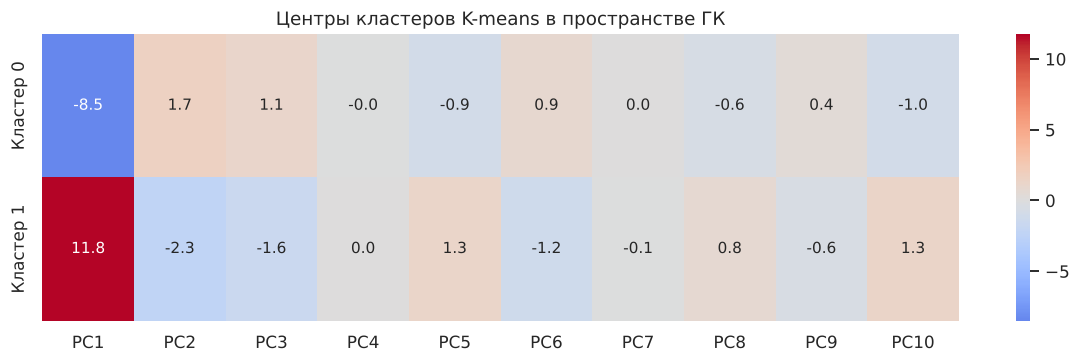

In [25]:
cent = pd.DataFrame(km.cluster_centers_, columns=pc_cols, index=[f"Кластер {i}" for i in range(K)])
plt.figure(figsize=(11, 2.2 + K * .6))
sns.heatmap(cent, annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Центры кластеров K-means в пространстве ГК")
plt.tight_layout()
save_fig("17_centroids")
plt.show()

Fs, Ps = stats.f_oneway(*[Xs[lab_km == k] for k in range(K)])
order = np.argsort(Ps)
m_ = len(Ps)
bh = np.minimum.accumulate((Ps[order] * m_ / (np.arange(m_) + 1))[::-1])[::-1]
padj = np.empty(m_)
padj[order] = np.minimum(bh, 1)
print(f"Генов с FDR < 0.05, различающихся между кластерами K-means: {(padj < .05).sum()} из {m_}")

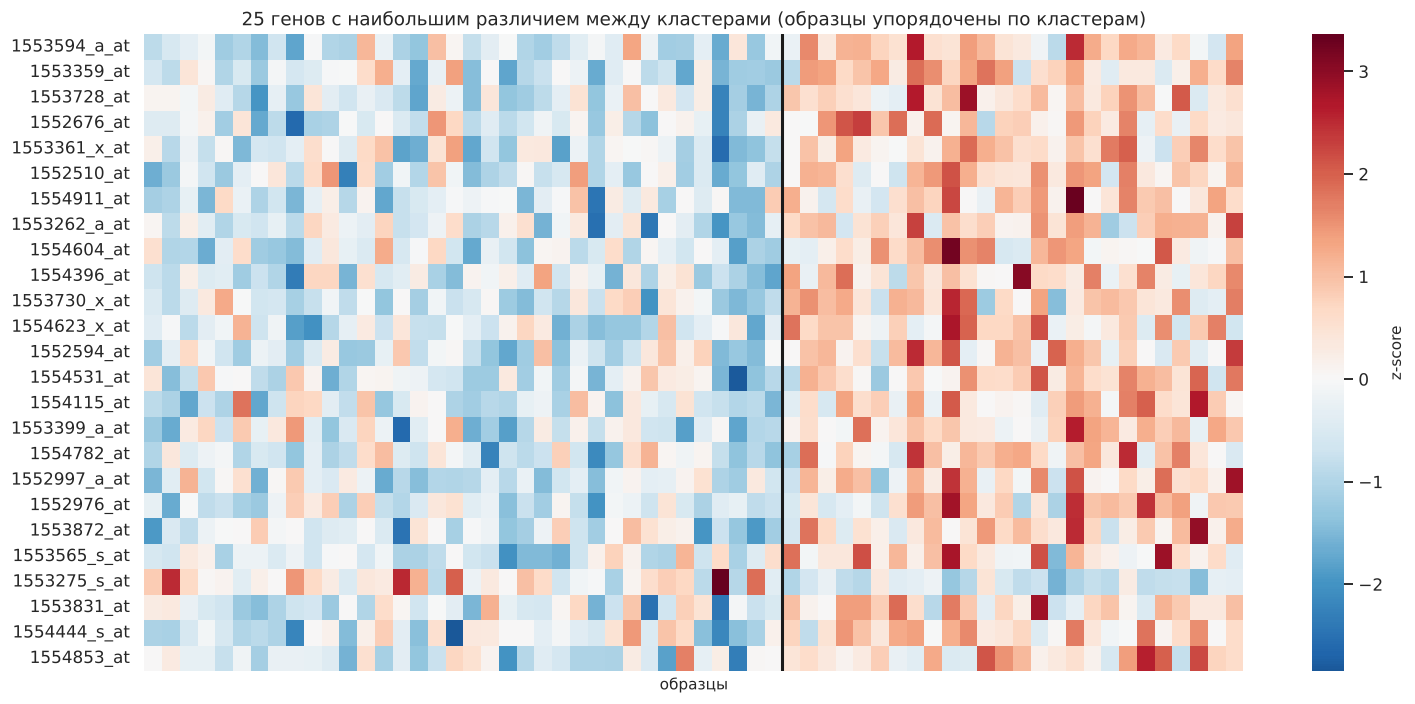

,mean_z_cluster0,mean_z_cluster1,FDR
gene,,,
1553594_a_at,-0.546,0.756,2.8e-05
1553359_at,-0.540,0.747,2.8e-05
1553728_at,-0.532,0.736,3.5e-05
1552676_at,-0.515,0.713,7.6e-05
1553361_x_at,-0.514,0.711,7.6e-05
1552510_at,-0.508,0.704,9.2e-05
1554911_at,-0.504,0.697,1.1e-04
1553262_a_at,-0.493,0.683,1.6e-04
1554604_at,-0.492,0.681,1.6e-04


In [26]:
top = pd.Series(Fs, index=gene_cols).sort_values(ascending=False).head(25).index
gm = pd.DataFrame(Xs, columns=gene_cols, index=X.index)[top]
srt = np.argsort(lab_km, kind="stable")

plt.figure(figsize=(14, 6.5))
sns.heatmap(gm.iloc[srt].T, cmap="RdBu_r", center=0, xticklabels=False, cbar_kws={"label": "z-score"})
for b in np.cumsum(np.bincount(lab_km))[:-1]:
    plt.axvline(b, c="k", lw=2)
plt.title("25 генов с наибольшим различием между кластерами (образцы упорядочены по кластерам)")
plt.xlabel("образцы"); plt.tight_layout()
save_fig("18_top_genes_heatmap")
plt.show()

top_tab = pd.DataFrame({"gene": top,
                        "mean_z_cluster0": [Xs[lab_km == 0][:, gene_cols.index(g)].mean() for g in top],
                        "mean_z_cluster1": [Xs[lab_km == 1][:, gene_cols.index(g)].mean() for g in top],
                        "FDR": [f"{v:.1e}" for v in padj[[gene_cols.index(g) for g in top]]]}).set_index("gene")
top_tab[["mean_z_cluster0", "mean_z_cluster1"]] = top_tab[["mean_z_cluster0", "mean_z_cluster1"]].round(3)
display(top_tab.head(10))


**Центры кластеров.**

- Центроиды K-means в пространстве ГК различаются по нескольким компонентам; расстояние между ними (**≈ 21**, раздел 5.4.1) сопоставимо с радиусом облака, но меньше среднего внутрикластерного расстояния.
- **Гены-«маркеры» кластеров.** Различия между кластерами по экспрессии статистически значимы для **375 из 1935** зондов (FDR < 0.05; около 19 %). Для 25 лучших генов кластер 0 имеет средние z-оценки около **−0.5**, а кластер 1 — около **+0.7**: то есть кластер 1 — это группа образцов с **повышенной экспрессией** целого набора генов, а кластер 0 — с пониженной. На тепловой карте это видно как два «блока» — слаженное смещение многих генов в одну сторону, а не точечные различия.
- **Важная оговорка.** Тест на различие экспрессии между кластерами «циркулярен»: кластеры построены именно по этим данным, поэтому генам заведомо «суждено» различаться. Значения FDR — описательные, не доказательные; для биологических выводов нужна независимая валидация (другая когорта).
- Согласованный сдвиг сотен генов в одну сторону — характерный признак **технического или тканевого фактора** (качество/количество РНК, доля опухолевых клеток в образце, батч набора `df_combined`), а не обязательно биологического подтипа болезни.


### 6.3. Содержательная интерпретация: связь кластеров с клиническими данными

In [27]:
rows = []
for c in ["Dukes Stage", "Gender", "Location", "DFS event", "Adj_Radio", "Adj_Chem"]:
    ct = pd.crosstab(lab_km, meta[c].values)
    rows.append((c, stats.chi2_contingency(ct)[1], stats.fisher_exact(ct)[1] if ct.shape == (2, 2) else np.nan))
for c in ["Age (in years)", "DFS (in months)"]:
    rows.append((c, stats.kruskal(*[meta[c].values[lab_km == k] for k in range(K)])[1], np.nan))
print("Связь кластеров K-means с клиническими признаками (p-value: χ² / Крускал–Уоллис; Фишер для таблиц 2×2):")
display(pd.DataFrame(rows, columns=["Признак", "p-value", "Fisher p (2×2)"]).set_index("Признак").round(3))

display(pd.crosstab(lab_km, meta["Dukes Stage"].values, rownames=["кластер"], colnames=["стадия Дьюка"]))
display(meta.assign(cluster=lab_km).groupby("cluster")[["Age (in years)", "DFS (in months)", "DFS event", "Adj_Radio", "Adj_Chem"]].mean().round(2))

Связь кластеров K-means с клиническими признаками (p-value: χ² / Крускал–Уоллис; Фишер для таблиц 2×2):

,p-value,Fisher p (2×2)
Признак,,
Dukes Stage,0.603,NaN
Gender,1.000,1.000
Location,0.182,NaN
DFS event,1.000,1.000
Adj_Radio,1.000,1.000
Adj_Chem,0.578,0.451
Age (in years),0.994,NaN
DFS (in months),0.104,NaN


стадия Дьюка,A,B,C,D
кластер,,,,
0,10,8,13,5
1,6,6,7,7


,Age (in years),DFS (in months),DFS event,Adj_Radio,Adj_Chem
cluster,,,,,
0,61.33,46.97,0.58,0.53,0.53
1,60.81,34.58,0.62,0.54,0.42



**Связь кластеров с клиническими данными (K-means, $k = 2$).**

- Ни один признак не связан с кластером статистически значимо: стадия Дьюка (p = 0.603), пол (1.000), локализация (0.182), событие рецидива (1.000), лучевая терапия (1.000), химиотерапия (0.578), возраст (0.994). Распределение стадий почти одинаково в обоих кластерах (кластер 0: A/B/C/D = 10/8/13/5; кластер 1: 6/6/7/7).
- Единственное заметное (но **незначимое**) отличие — выживаемость без рецидива: **47.0 мес** в кластере 0 против **34.6 мес** в кластере 1 (p = 0.104, критерий Краскела–Уоллиса). Это лишь намёк, требующий проверки на большей выборке: при 62 пациентах и множестве проверенных признаков такое p-value вполне может быть случайным.
- Средний возраст (61.3 и 60.8 года) и доли получавших терапию различаются мало.
- **Содержательная интерпретация:** выделенные группы — это (скорее всего) два уровня общей «активности» экспрессии (кластер 1 — повышенная, кластер 0 — пониженная), не соответствующие стадии болезни, полу или локализации. Как маркер клинического исхода они не подтверждены.


### 6.4. Чувствительность к числу главных компонент

Проверим, насколько разбиение K-means ($k = 2$) зависит от выбора $N_{PC}$ (ARI относительно базового разбиения на 10 ГК).

In [28]:
rows = []
for n_ in [2, 5, 10, 20, 40]:
    Zn = PCA(n_components=n_, random_state=RANDOM_STATE).fit_transform(Xs)
    y = KMeans(2, n_init=10, random_state=RANDOM_STATE).fit_predict(Zn)
    rows.append(dict(n_PC=n_, silhouette=silhouette_score(Zn, y), sizes=tuple(int(v) for v in np.bincount(y)),
                     ARI_vs_base=adjusted_rand_score(lab_km, y)))
y = KMeans(2, n_init=10, random_state=RANDOM_STATE).fit_predict(Xs)
rows.append(dict(n_PC="все гены", silhouette=silhouette_score(Xs, y), sizes=tuple(int(v) for v in np.bincount(y)),
                 ARI_vs_base=adjusted_rand_score(lab_km, y)))
sens = pd.DataFrame(rows).set_index("n_PC")
display(sens.round(3))

,silhouette,sizes,ARI_vs_base
n_PC,,,
2,0.392,"(34, 28)",0.873
5,0.208,"(35, 27)",0.935
10,0.157,"(36, 26)",1.000
20,0.096,"(34, 28)",0.873
40,0.060,"(34, 28)",0.873
все гены,0.042,"(34, 28)",0.873



**Чувствительность к числу главных компонент.**

- Разбиение на 2 кластера **воспроизводимо** при любом числе компонент: ARI относительно базового разбиения (10 ГК) равен **0.87–0.94** при 2, 5, 20, 40 ГК и даже при использовании всех 1935 генов (0.873). Размеры кластеров почти не меняются (34–36 и 26–28).
- **Silhouette при этом падает** с **0.392 (2 ГК)** до **0.157 (10 ГК)**, 0.096 (20), 0.060 (40) и **0.042 (все гены)**. Причина: добавление «шумовых» компонент увеличивает размерность и сглаживает контраст расстояний. Высокий силуэт в 2 ГК — отчасти «оптимистичное» значение (в 2D кластеры «выглядят» разделёнными из-за проекции).
- Следовательно, разбиение на 2 группы **определяется первыми компонентами** (основной сигнал) и не является артефактом выбора $N_{PC} = 10$; но **качество разделения** зависит от числа компонент и остаётся низким при полном учёте данных.


## 7. Сравнительный анализ методов

Соберём в одну таблицу основные внутренние метрики, внешнее соответствие стадии Дьюка и устойчивость обоих методов.

,K-means,Ward
Размеры кластеров,"(36, 26)","(29, 33)"
Silhouette,0.157016,0.12077
Calinski–Harabasz,10.740907,9.077207
Davies–Bouldin,2.145158,2.310397
Dunn,0.13174,0.173973
WCSS,38056.442028,38973.017945
ARI vs Дьюк,-0.00599,-0.022689
"Устойчивость (ARI, k=2)",0.7914,0.285407


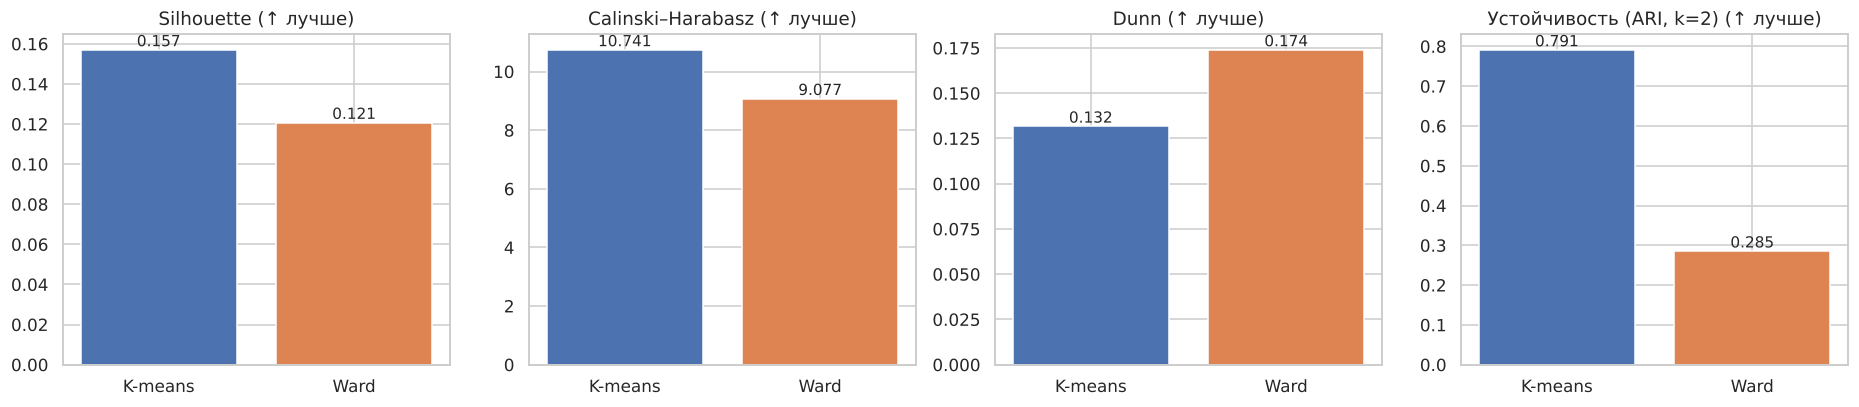

In [29]:
comparison = pd.DataFrame({
    "K-means": {"Размеры кластеров": str(tuple(int(v) for v in np.bincount(lab_km))),
                "Silhouette": tab_int.loc["Silhouette", "K-means"],
                "Calinski–Harabasz": tab_int.loc["Calinski–Harabasz", "K-means"],
                "Davies–Bouldin": tab_int.loc["Davies–Bouldin", "K-means"],
                "Dunn": tab_int.loc["Dunn", "K-means"],
                "WCSS": tab_int.loc["WCSS", "K-means"],
                "ARI vs Дьюк": ext.loc[("Dukes Stage", "K-means"), "ARI"],
                "Устойчивость (ARI, k=2)": st.loc[2, "K-means"]},
    "Ward": {"Размеры кластеров": str(tuple(int(v) for v in np.bincount(lab_hc))),
             "Silhouette": tab_int.loc["Silhouette", "Ward"],
             "Calinski–Harabasz": tab_int.loc["Calinski–Harabasz", "Ward"],
             "Davies–Bouldin": tab_int.loc["Davies–Bouldin", "Ward"],
             "Dunn": tab_int.loc["Dunn", "Ward"],
             "WCSS": tab_int.loc["WCSS", "Ward"],
             "ARI vs Дьюк": ext.loc[("Dukes Stage", "Ward"), "ARI"],
             "Устойчивость (ARI, k=2)": st.loc[2, "Ward"]},
})
display(comparison)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, metric, better in zip(axes, ["Silhouette", "Calinski–Harabasz", "Dunn", "Устойчивость (ARI, k=2)"],
                              ["↑", "↑", "↑", "↑"]):
    vals = [float(comparison.loc[metric, "K-means"]), float(comparison.loc[metric, "Ward"])]
    ax.bar(["K-means", "Ward"], vals, color=["#4c72b0", "#dd8452"])
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom")
    ax.set_title(f"{metric} ({better} лучше)")
fig.tight_layout()
save_fig("19_methods_comparison")
plt.show()

In [30]:
# Сохраним итоговые таблицы и разметку образцов рядом с ноутбуком — пригодятся для отчёта
ev.round(4).to_csv(RESULT_DIR / "k_selection_metrics.csv")
tab_int.round(4).to_csv(RESULT_DIR / "internal_metrics.csv")
ext.round(4).to_csv(RESULT_DIR / "external_metrics.csv")
st.round(4).to_csv(RESULT_DIR / "stability.csv")
pk.round(4).to_csv(RESULT_DIR / "kmeans_param_k.csv")
comparison.to_csv(RESULT_DIR / "methods_comparison.csv")
pd.DataFrame({"kmeans_cluster": lab_km, "ward_cluster": lab_hc}, index=X.index).to_csv(RESULT_DIR / "cluster_labels.csv")

print("Сохранено в", RESULT_DIR.resolve())
print("Файлы:", sorted(p.name for p in RESULT_DIR.glob("*")))
print("Рисунки:", len(list(FIG_DIR.glob("*.png"))), "шт. в", FIG_DIR.resolve())

Сохранено в /home/claude/nb/run/results_clustering
Файлы: ['cluster_labels.csv', 'external_metrics.csv', 'internal_metrics.csv', 'k_selection_metrics.csv', 'kmeans_param_k.csv', 'methods_comparison.csv', 'stability.csv']
Рисунки: 19 шт. в /home/claude/nb/run/figures_clustering


### 7.1. Интерпретация результатов

| Критерий | Лучший метод | Значение |
|:---|:---|---:|
| Silhouette | K-means | 0.157 (против 0.121) |
| Calinski–Harabasz | K-means | 10.74 (против 9.08) |
| Davies–Bouldin (меньше — лучше) | K-means | 2.15 (против 2.31) |
| WCSS (компактность) | K-means | 38 056 (против 38 973) |
| Dunn | Ward | 0.174 (против 0.132) |
| Мин. расстояние между кластерами | Ward | 13.4 (против 10.1) |
| Устойчивость, $k = 2$ (ARI) | K-means | 0.791 (против 0.285) |
| Соответствие стадии Дьюка (ARI) | — | ≈ 0 у обоих |

- **K-means лучше по большинству метрик и существенно устойчивее** при $k = 2$: он выигрывает по Silhouette, CH, DB и WCSS и воспроизводится на подвыборках (ARI 0.79 против 0.29).
- **Метод Уорда** детерминирован, даёт дендрограмму (полезна для визуализации выбросов), но при $k = 2$ его разбиение определяется несколькими пограничными образцами; лучшие значения Dunn обусловлены единичными ближайшими парами точек.
- **Согласованность методов** умеренная (ARI = 0.593): ядро групп общее, граница — разная.
- **Внешние метрики одинаково низки (ARI ≈ 0)** — выбор метода не влияет на (отсутствующую) связь с клиникой.
- **DBSCAN** (раздел 5.5.2) не нашёл содержательных плотностных кластеров, зато стабильно выделяет три образца-выброса.



## 8. Заключение

В работе выполнена кластеризация 62 образцов опухолевой ткани по экспрессии 1935 генов (Gene Expression Cancer Dataset, `df_combined.csv`) методами K-means и иерархической кластеризации (Уорд) с дополнительным исследованием DBSCAN.

**Что сделано:**

1. Проведён дескриптивный анализ: 62 × 1935 признака, пропусков нет; распределения экспрессии близки к нормальным (нормальность не отвергается у 64.7 % генов), 54.5 % генов имеют низкую дисперсию, корреляции между генами очень слабы.
2. Выявлены **три многомерных выброса** (GSM877144, GSM877147, GSM877186) — по числу экстремальных значений, по расстоянию в пространстве ГК, по дендрограмме и по поведению K-means при $k \ge 3$.
3. Выполнена стандартизация (`StandardScaler`), обоснованная выбором евклидовой метрики и различием std генов в ~40 раз; из-за $n \ll p$ данные сжаты PCA до 10 компонент (37.5 % дисперсии).
4. Проверены условия применимости: клинические метки исключены из признаков; статистика Хопкинса 0.668 лишь немного выше нулевой модели (0.581) — **кластерная структура слабая**; матрица диаграмм рассеяния показывает единое облако.
5. Число кластеров подобрано методами локтя, silhouette, Calinski–Harabasz, Davies–Bouldin и по дендрограмме; выбрано **$k = 2$**.
6. Реализованы K-means (`n_init = 10`) и метод Уорда; рассчитаны внутренние (Silhouette, CH, DB, Dunn, WCSS, внутрикластерные расстояния, расстояния между центроидами) и внешние (ARI, NMI, Жаккар, Fowlkes–Mallows, Homogeneity, Completeness) метрики; построена сравнительная таблица.
7. Исследовано влияние параметров ($k$ для K-means; $\varepsilon$ и `min_samples` для DBSCAN), устойчивость на 100 подвыборках и чувствительность к числу компонент PCA.
8. Кластеры визуализированы в PCA-пространстве, проанализированы центры кластеров, гены-маркеры и связь с клиническими данными.

**Основные выводы:**

- **Структура данных:** слабо выраженная. Silhouette 0.157 (K-means) и 0.121 (Ward) в пространстве 10 ГК и около 0.04 — в полном пространстве; Davies–Bouldin > 2; внутрикластерные расстояния превышают расстояния между центрами. Кластеры существенно перекрываются.
- **Сравнение методов.** K-means (k = 2): лучше по Silhouette, CH, DB, WCSS и значительно устойчивее (ARI на подвыборках 0.79 против 0.29 у Уорда). Метод Уорда даёт дендрограмму и чуть больший зазор между кластерами (Dunn 0.174 против 0.132), но нестабилен при $k = 2$. Методы согласуются умеренно (ARI = 0.59). DBSCAN непригоден: либо доля шума от 37 %, либо единый кластер.
- **Число кластеров.** При $k \ge 3$ дополнительные «кластеры» — это 1–2 выброса; Davies–Bouldin при этом улучшается формально. Разбиения с $k \ge 4$ неустойчивы (ARI 0.34–0.46 у K-means).
- **Интерпретация кластеров.** Две группы различаются сдвигом экспрессии сотен генов (375 из 1935, FDR < 0.05): кластер 1 (26 образцов) — повышенная экспрессия, кластер 0 (36) — пониженная. Однако кластеры **не соответствуют** стадии Дьюка, полу, локализации, исходу и терапии (ARI ≈ 0, все p > 0.1); наибольший, но незначимый контраст — выживаемость без рецидива (47.0 против 34.6 мес, p = 0.104).
- **Применимость методов.** Для данных типа «мало образцов — тысячи признаков» кластеризацию следует проводить **после снижения размерности** (PCA): в полном пространстве силуэт близок к нулю. Предпочтителен K-means с `n_init ≥ 10`; иерархическая кластеризация полезна для визуального поиска выбросов; DBSCAN — для детекции выбросов.

**Ограничения:** малая выборка (62 образца) при 1935 признаках; слабая кластерная структура; наличие выбросов; клинические метки несбалансированы (77 % мужчин, 2 образца с локализацией `Colon`); возможные батч-эффекты в объединённом наборе (`df_combined`). Полученные группы нельзя считать молекулярными подтипами заболевания без независимой валидации. Для дальнейшей работы целесообразны: предварительный отбор генов (например, по вариабельности или по известным сигнатурам), коррекция батч-эффектов, увеличение выборки, использование консенсусной кластеризации и проверка на внешней когорте.



## 9. Список источников

1. Pedregosa F. et al. Scikit-learn: Machine Learning in Python // Journal of Machine Learning Research. — 2011. — Vol. 12. — P. 2825–2830.
2. Rousseeuw P. J. Silhouettes: a graphical aid to the interpretation and validation of cluster analysis // Journal of Computational and Applied Mathematics. — 1987. — Vol. 20. — P. 53–65.
3. Caliński T., Harabasz J. A dendrite method for cluster analysis // Communications in Statistics. — 1974. — Vol. 3, No. 1. — P. 1–27.
4. Davies D. L., Bouldin D. W. A cluster separation measure // IEEE Transactions on Pattern Analysis and Machine Intelligence. — 1979. — Vol. PAMI-1, No. 2. — P. 224–227.
5. Ward J. H. Hierarchical grouping to optimize an objective function // Journal of the American Statistical Association. — 1963. — Vol. 58. — P. 236–244.
6. MacQueen J. Some methods for classification and analysis of multivariate observations // Proc. 5th Berkeley Symposium on Mathematical Statistics and Probability. — 1967. — Vol. 1. — P. 281–297.
7. Ester M., Kriegel H.-P., Sander J., Xu X. A density-based algorithm for discovering clusters in large spatial databases with noise // Proc. KDD-96. — 1996. — P. 226–231.
8. Hopkins B., Skellam J. G. A new method for determining the type of distribution of plant individuals // Annals of Botany. — 1954. — Vol. 18. — P. 213–227.
9. Hubert L., Arabie P. Comparing partitions // Journal of Classification. — 1985. — Vol. 2. — P. 193–218.
10. Benjamini Y., Hochberg Y. Controlling the false discovery rate: a practical and powerful approach to multiple testing // Journal of the Royal Statistical Society B. — 1995. — Vol. 57. — P. 289–300.
11. Документация scikit-learn, раздел Clustering: https://scikit-learn.org/stable/modules/clustering.html
12. Gene Expression Omnibus (GEO), серия образцов GSM877xxx: https://www.ncbi.nlm.nih.gov/geo/


## Приложение  Полный листинг программного кода



### Листинг: Импорт, загрузка, дескриптивный анализ, распределения (разделы 1–2.4)

**Ячейка 1**

```python
from pathlib import Path
import os
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import cdist, pdist

import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score, silhouette_samples, calinski_harabasz_score,
    davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score,
    homogeneity_score, completeness_score, fowlkes_mallows_score,
    pair_confusion_matrix,
)

RANDOM_STATE = 42
RS = RANDOM_STATE
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "font.size": 10,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

FIG_DIR = Path("figures_clustering")
FIG_DIR.mkdir(exist_ok=True)
RESULT_DIR = Path("results_clustering")
RESULT_DIR.mkdir(exist_ok=True)

def save_fig(name):
    """Сохраняет текущий рисунок в figures_clustering/<name>.png"""
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
```

**Ячейка 2**

```python
try:
    from google.colab import files
    if not os.path.exists("df_combined.csv"):
        print("Загрузите файл df_combined.csv")
        files.upload()
except ImportError:
    pass   # локальный запуск

PATH = "df_combined.csv" if os.path.exists("df_combined.csv") else "/mnt/user-data/uploads/df_combined.csv"
df = pd.read_csv(PATH, index_col=0).set_index("ID_REF")

meta_cols = ["Age (in years)", "Dukes Stage", "Gender", "Location",
             "DFS (in months)", "DFS event", "Adj_Radio", "Adj_Chem"]
gene_cols = [c for c in df.columns if c not in meta_cols]
meta, X = df[meta_cols], df[gene_cols]

print("Размерность таблицы:", df.shape)
print(f"Образцов: {X.shape[0]}, генных зондов (признаков): {X.shape[1]}")
print("\nТипы данных:")
print(df.dtypes.astype(str).value_counts().to_string())
print("\nПропусков всего:", int(df.isna().sum().sum()), "| дубликатов строк:", int(df.duplicated().sum()))
print("Диапазон экспрессии (log2): от", round(X.values.min(), 2), "до", round(X.values.max(), 2))
```

**Ячейка 3**

```python
# Сводная информация по клиническим переменным
summary = pd.DataFrame({
    "dtype": meta.dtypes.astype(str),
    "non_null": meta.notna().sum(),
    "missing": meta.isna().sum(),
    "unique": meta.nunique(),
})
display(summary)
display(meta.describe().T.round(2))
for c in ["Dukes Stage", "Gender", "Location", "DFS event", "Adj_Radio", "Adj_Chem"]:
    print(f"{c:12s}", meta[c].value_counts().to_dict())
```

**Ячейка 4**

```python
# Первые строки матрицы экспрессии
display(X.iloc[:5, :8])
```

**Ячейка 5**

```python
rng = np.random.default_rng(RANDOM_STATE)
sample_genes = rng.choice(gene_cols, 12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(15, 8))
for ax, g in zip(axes.ravel(), sample_genes):
    sns.histplot(X[g], kde=True, ax=ax, bins=15, color="#4c72b0")
    ax.set_title(f"{g}  (skew={X[g].skew():.2f})", fontsize=10)
    ax.set_xlabel("")
fig.suptitle("Распределение экспрессии 12 случайных генов", fontsize=14, y=1.0)
fig.tight_layout()
save_fig("01_gene_histograms")
plt.show()
```

**Ячейка 6**

```python
skew = X.skew()
sh_p = np.array([stats.shapiro(X[g])[1] for g in gene_cols])
print(f"Доля генов, для которых нормальность НЕ отвергается (Шапиро–Уилк, p > 0.05): {(sh_p > 0.05).mean():.1%}")
print(f"Асимметрия: медиана = {skew.median():.2f};  |skew| > 1 у {(skew.abs() > 1).mean():.1%} генов")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(X.values.ravel(), bins=60, ax=axes[0], color="#4c72b0")
axes[0].set_title("Все значения экспрессии (log2)")
sns.histplot(skew, bins=40, ax=axes[1], color="#55a868")
axes[1].set_title("Асимметрия по генам"); axes[1].axvline(0, c="r", ls="--")
sns.histplot(sh_p, bins=30, ax=axes[2], color="#c44e52")
axes[2].set_title("p-value теста Шапиро–Уилка"); axes[2].axvline(0.05, c="k", ls="--")
fig.tight_layout()
save_fig("02_distribution_summary")
plt.show()
```

### Листинг: Выбросы, информативность, предобработка, PCA (разделы 2.5–3.3)

**Ячейка 7**

```python
Zr = (X - X.mean()) / X.std()
n_out = (Zr.abs() > 3).sum(axis=1)
q1, q3 = X.quantile(.25), X.quantile(.75)
iqr = q3 - q1
iqr_out = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).sum(axis=1)
print(f"Доля значений с |z| > 3: {(Zr.abs() > 3).values.mean():.2%};  вне границ 1.5·IQR: {iqr_out.sum() / X.size:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
n_out.sort_values(ascending=False).plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Число генов с |z| > 3 у каждого образца")
axes[0].set_xticklabels([]); axes[0].set_xlabel("образцы (по убыванию)")
sns.boxplot(data=X.T, ax=axes[1], fliersize=1, color="#8da0cb")
axes[1].set_title("Распределение экспрессии по образцам")
axes[1].set_xticklabels([]); axes[1].set_xlabel("образцы")
fig.tight_layout()
save_fig("03_outliers")
plt.show()

print("Образцы с наибольшим числом экстремальных значений:")
display(n_out.sort_values(ascending=False).head(6).to_frame("genes_|z|>3"))
```

**Ячейка 8**

```python
var = X.var()
corr = X.corr().values
iu = np.triu_indices_from(corr, 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
sns.histplot(var, bins=60, ax=axes[0], color="#4c72b0")
axes[0].set_yscale("log"); axes[0].set_title("Дисперсия генов (до стандартизации)")
axes[1].scatter(X.mean(), X.std(), s=5, alpha=.5, color="#55a868")
axes[1].set_xlabel("среднее"); axes[1].set_ylabel("стандартное отклонение")
axes[1].set_title("Среднее vs стандартное отклонение")
sns.histplot(corr[iu], bins=60, ax=axes[2], color="#c44e52")
axes[2].set_title("Попарные корреляции генов")
fig.tight_layout()
save_fig("04_informativeness")
plt.show()

print(f"Гены с дисперсией < 0.05: {(var < 0.05).sum()} ({(var < 0.05).mean():.1%});  медиана дисперсии: {var.median():.3f}")
print(f"Пар генов с |r| > 0.7: {(np.abs(corr[iu]) > 0.7).mean():.2%};  с |r| > 0.5: {(np.abs(corr[iu]) > 0.5).mean():.2%}")
```

**Ячейка 9**

```python
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

std_before = X.std()
print("Std генов ДО стандартизации:  min = %.3f, медиана = %.3f, max = %.3f" % (std_before.min(), std_before.median(), std_before.max()))
print("Std генов ПОСЛЕ стандартизации: min = %.3f, max = %.3f; max|mean| = %.1e" % (Xs.std(0).min(), Xs.std(0).max(), np.abs(Xs.mean(0)).max()))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(std_before, bins=50, ax=axes[0], color="#4c72b0"); axes[0].set_title("Std генов до стандартизации")
axes[1].plot(np.sort(std_before.values), label="до", c="#4c72b0")
axes[1].plot(np.sort(Xs.std(0)), label="после", c="#55a868")
axes[1].set_yscale("log"); axes[1].legend()
axes[1].set_title("Std генов (отсортировано): до и после"); axes[1].set_xlabel("гены")
fig.tight_layout()
save_fig("05_scaling")
plt.show()
```

**Ячейка 10**

```python
pca_full = PCA(random_state=RANDOM_STATE).fit(Xs)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(range(1, 21), evr[:20], color="#4c72b0")
axes[0].set_title("Scree plot (первые 20 ГК)"); axes[0].set_xlabel("номер ГК"); axes[0].set_ylabel("доля дисперсии")
axes[1].plot(range(1, len(cum) + 1), cum, "o-", ms=3)
axes[1].axhline(0.8, c="r", ls="--", label="80 %"); axes[1].legend()
axes[1].set_title("Накопленная доля дисперсии"); axes[1].set_xlabel("число ГК")
fig.tight_layout()
save_fig("06_pca_variance")
plt.show()

print("Накопленная дисперсия: 2 ГК = %.1f%%, 5 ГК = %.1f%%, 10 ГК = %.1f%%; для 80%% нужно %d ГК"
      % (cum[1] * 100, cum[4] * 100, cum[9] * 100, (cum < .8).sum() + 1))

N_PC = 10
pca = PCA(n_components=N_PC, random_state=RANDOM_STATE)
Z = pca.fit_transform(Xs)
pc_cols = [f"PC{i + 1}" for i in range(N_PC)]
Zdf = pd.DataFrame(Z, columns=pc_cols, index=X.index)
print("Форма матрицы в пространстве ГК:", Z.shape)
```

**Ячейка 11**

```python
d_c = np.linalg.norm(Z - Z.mean(0), axis=1)
thr = np.median(d_c) + 3 * stats.median_abs_deviation(d_c, scale="normal")
out_pc = pd.Series(d_c, index=X.index).sort_values(ascending=False)
print(f"Порог выброса (медиана + 3·MAD) = {thr:.1f}")
print("Образцы с наибольшим расстоянием от центра в пространстве ГК:")
display(out_pc.head(6).round(1).to_frame("distance"))

y3 = KMeans(3, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
small = [k for k in range(3) if (y3 == k).sum() <= 3]
print("Малые кластеры при k=3 (размер ≤ 3):", {k: X.index[y3 == k].tolist() for k in small})

plt.figure(figsize=(7, 4))
sns.histplot(d_c, bins=20, color="#4c72b0")
plt.axvline(thr, c="r", ls="--", label="порог выброса"); plt.legend()
plt.title("Расстояние образцов от центра облака (10 ГК)")
plt.tight_layout()
save_fig("07_pca_outliers")
plt.show()
```

**Ячейка 12**

```python
def hopkins(A, m=None, n_rep=100, seed=RANDOM_STATE):
    r = np.random.default_rng(seed)
    n, d = A.shape
    m = m or max(5, int(.2 * n))
    nn = NearestNeighbors(n_neighbors=2).fit(A)
    lo, hi = A.min(0), A.max(0)
    res = []
    for _ in range(n_rep):
        idx = r.choice(n, m, replace=False)
        w = nn.kneighbors(A[idx], 2)[0][:, 1]          # расстояние до ближайшего *другого* реального объекта
        U = r.uniform(lo, hi, (m, d))
        u = nn.kneighbors(U, 1)[0][:, 0]               # расстояние от случайной точки до ближайшего реального
        res.append(u.sum() / (u.sum() + w.sum()))
    return np.mean(res)

rp = np.random.default_rng(RANDOM_STATE)
Xperm = np.column_stack([rp.permutation(Xs[:, j]) for j in range(Xs.shape[1])])
Zperm = PCA(n_components=N_PC, random_state=RANDOM_STATE).fit_transform(Xperm)

H_real, H_perm = hopkins(Z), hopkins(Zperm)
print(f"Hopkins (реальные данные, {N_PC} ГК): {H_real:.3f}")
print(f"Hopkins (нулевая модель — гены независимо перемешаны): {H_perm:.3f}")
```

### Листинг: Применимость кластеризации, выбор k, дендрограмма, итоговые разбиения (разделы 4–5.3)

**Ячейка 13**

```python
g = sns.pairplot(Zdf.iloc[:, :5], diag_kind="kde",
                 plot_kws=dict(s=25, alpha=.7, edgecolor="k", linewidth=.3, color="#4c72b0"))
g.fig.suptitle("Матрица диаграмм рассеяния по первым 5 главным компонентам", y=1.02, fontsize=14)
g.savefig(FIG_DIR / "08_scatter_matrix.png", bbox_inches="tight")
plt.show()
```

**Ячейка 14**

```python
K_RANGE = range(2, 11)

def eval_k(Zspace):
    rows = []
    Zl = linkage(Zspace, "ward")
    for k in K_RANGE:
        km_ = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Zspace)
        ag = fcluster(Zl, k, "maxclust")
        rows.append(dict(
            k=k, inertia=km_.inertia_,
            sil_km=silhouette_score(Zspace, km_.labels_),
            ch_km=calinski_harabasz_score(Zspace, km_.labels_),
            db_km=davies_bouldin_score(Zspace, km_.labels_),
            sil_hc=silhouette_score(Zspace, ag),
            ch_hc=calinski_harabasz_score(Zspace, ag),
            db_hc=davies_bouldin_score(Zspace, ag)))
    return pd.DataFrame(rows).set_index("k")

ev = eval_k(Z)            # пространство 10 ГК
ev_full = eval_k(Xs)      # все 1935 генов
display(ev.round(3))
```

**Ячейка 15**

```python
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
axes[0].plot(ev.index, ev.inertia, "o-"); axes[0].set_title("Метод локтя (K-means, inertia)")
axes[1].plot(ev.index, ev.sil_km, "o-", label="K-means")
axes[1].plot(ev.index, ev.sil_hc, "s--", label="Ward")
axes[1].set_title("Silhouette (пространство 10 ГК)"); axes[1].legend()
axes[2].plot(ev.index, ev.ch_km, "o-", label="K-means")
axes[2].plot(ev.index, ev.ch_hc, "s--", label="Ward")
axes[2].set_title("Calinski–Harabasz"); axes[2].legend()
axes[3].plot(ev_full.index, ev_full.sil_km, "o-", label="K-means")
axes[3].plot(ev_full.index, ev_full.sil_hc, "s--", label="Ward")
axes[3].set_title("Silhouette (все 1935 генов)"); axes[3].legend()
for a in axes:
    a.set_xlabel("k")
fig.tight_layout()
save_fig("09_choose_k")
plt.show()
print("Лучший k по silhouette: K-means =", ev.sil_km.idxmax(), "| Ward =", ev.sil_hc.idxmax())
```

**Ячейка 16**

```python
rows = []
for m_ in ["ward", "average", "complete", "single"]:
    Lm = linkage(Z, m_)
    rows.append((m_, cophenet(Lm, pdist(Z))[0]))
print("Кофенетическая корреляция:")
display(pd.DataFrame(rows, columns=["linkage", "cophenetic"]).set_index("linkage").round(3))

L = linkage(Z, "ward")
plt.figure(figsize=(15, 5))
dendrogram(L, labels=X.index.tolist(), leaf_rotation=90, leaf_font_size=7, color_threshold=0.7 * L[-1, 2])
plt.title("Дендрограмма (метод Уорда, пространство 10 ГК)")
plt.ylabel("расстояние слияния")
plt.tight_layout()
save_fig("10_dendrogram")
plt.show()
print("Последние 8 слияний (высоты):", np.round(L[-8:, 2], 1))
```

**Ячейка 17**

```python
K = 2
km = KMeans(K, n_init=10, random_state=RANDOM_STATE).fit(Z)
lab_km = km.labels_
lab_hc = fcluster(L, K, "maxclust") - 1

print("Размеры кластеров  K-means:", np.bincount(lab_km), "| Ward:", np.bincount(lab_hc))
print("\nТаблица сопряжённости методов:")
display(pd.crosstab(lab_km, lab_hc, rownames=["K-means"], colnames=["Ward"]))
```

### Листинг: Метрики качества, влияние параметров, устойчивость (разделы 5.4–5.6)

**Ячейка 18**

```python
def internal_metrics(A_, y):
    ks = np.unique(y)
    cents = np.array([A_[y == k].mean(0) for k in ks])
    intra = [pdist(A_[y == k]).mean() if (y == k).sum() > 1 else 0 for k in ks]
    diam = [pdist(A_[y == k]).max() if (y == k).sum() > 1 else 0 for k in ks]
    wcss = sum(((A_[y == k] - cents[i]) ** 2).sum() for i, k in enumerate(ks))
    inter_min = min(cdist(A_[y == a], A_[y == b]).min() for i, a in enumerate(ks) for b in ks[i + 1:])
    return {"Silhouette": silhouette_score(A_, y),
            "Calinski–Harabasz": calinski_harabasz_score(A_, y),
            "Davies–Bouldin": davies_bouldin_score(A_, y),
            "Dunn": inter_min / max(diam),
            "WCSS": wcss,
            "Ср. внутрикласт. расстояние": np.mean(intra),
            "Ср. расстояние между центроидами": pdist(cents).mean(),
            "Мин. расстояние между кластерами": inter_min}

tab_int = pd.DataFrame({"K-means": internal_metrics(Z, lab_km), "Ward": internal_metrics(Z, lab_hc)})
display(tab_int.round(3))

tab_int_full = pd.DataFrame({"K-means": internal_metrics(Xs, lab_km), "Ward": internal_metrics(Xs, lab_hc)})
print("Те же разбиения, метрики в исходном стандартизованном пространстве (1935 генов):")
display(tab_int_full.loc[["Silhouette", "Calinski–Harabasz", "Davies–Bouldin"]].round(3))

print("Согласованность двух методов: ARI = %.3f, NMI = %.3f"
      % (adjusted_rand_score(lab_km, lab_hc), normalized_mutual_info_score(lab_km, lab_hc)))
```

**Ячейка 19**

```python
sil_km_s = silhouette_samples(Z, lab_km)
sil_hc_s = silhouette_samples(Z, lab_hc)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, y, s) in zip(axes, [("K-means", lab_km, sil_km_s), ("Ward", lab_hc, sil_hc_s)]):
    yl = 0
    for k in np.unique(y):
        sk = np.sort(s[y == k])
        ax.fill_betweenx(np.arange(yl, yl + len(sk)), 0, sk, alpha=.7, label=f"кластер {k} (n={len(sk)})")
        yl += len(sk) + 2
    ax.axvline(s.mean(), c="r", ls="--")
    ax.set_title(f"{name}: silhouette по образцам (среднее = {s.mean():.3f})")
    ax.set_xlabel("silhouette"); ax.set_ylabel("образцы"); ax.legend()
fig.tight_layout()
save_fig("11_silhouette_samples")
plt.show()
print("Доля образцов с отрицательным silhouette: K-means = %.1f%%, Ward = %.1f%%"
      % ((sil_km_s < 0).mean() * 100, (sil_hc_s < 0).mean() * 100))
```

**Ячейка 20**

```python
def external_metrics(y, t):
    (tn, fp), (fn, tp) = pair_confusion_matrix(t, y)
    return {"ARI": adjusted_rand_score(t, y),
            "NMI": normalized_mutual_info_score(t, y),
            "Jaccard (по парам)": tp / (tp + fp + fn),
            "Fowlkes–Mallows": fowlkes_mallows_score(t, y),
            "Homogeneity": homogeneity_score(t, y),
            "Completeness": completeness_score(t, y)}

ext = {}
for c in ["Dukes Stage", "Gender", "Location", "DFS event", "Adj_Radio", "Adj_Chem"]:
    for name, y in [("K-means", lab_km), ("Ward", lab_hc)]:
        ext[(c, name)] = external_metrics(y, meta[c].values)
ext = pd.DataFrame(ext).T
ext.index.names = ["Признак", "Метод"]
display(ext.round(3))
```

**Ячейка 21**

```python
rows = []
for k in K_RANGE:
    y = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
    rows.append(dict(k=k, Silhouette=silhouette_score(Z, y), CH=calinski_harabasz_score(Z, y),
                     DB=davies_bouldin_score(Z, y), min_size=np.bincount(y).min(),
                     ARI_Dukes=adjusted_rand_score(meta["Dukes Stage"], y)))
pk = pd.DataFrame(rows).set_index("k")
display(pk.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(pk.index, pk.Silhouette, "o-"); axes[0].set_title("Silhouette")
axes[1].plot(pk.index, pk.DB, "o-", c="#c44e52"); axes[1].set_title("Davies–Bouldin (меньше — лучше)")
axes[2].bar(pk.index, pk.min_size, color="#55a868"); axes[2].set_title("Размер наименьшего кластера")
for a in axes:
    a.set_xlabel("k")
fig.tight_layout()
save_fig("12_param_k")
plt.show()
```

**Ячейка 22**

```python
nbr = NearestNeighbors(n_neighbors=4).fit(Z)
kd = np.sort(nbr.kneighbors(Z)[0][:, -1])
plt.figure(figsize=(6.5, 3.8))
plt.plot(kd)
plt.title("k-distance plot (k = 4) для выбора ε")
plt.ylabel("расстояние до 4-го соседа"); plt.xlabel("образцы (по возрастанию)")
plt.tight_layout()
save_fig("13_kdistance")
plt.show()

eps_grid = np.round(np.linspace(10, 24, 8), 1)
ms_grid = [2, 3, 4, 5, 6]
ncl = pd.DataFrame(index=ms_grid, columns=eps_grid, dtype=float)
noise = ncl.copy(); sil = ncl.copy()
for e in eps_grid:
    for m_ in ms_grid:
        y = DBSCAN(eps=e, min_samples=m_).fit_predict(Z)
        mask = y != -1
        ncl.loc[m_, e] = len(set(y)) - (1 if -1 in y else 0)
        noise.loc[m_, e] = 1 - mask.mean()
        sil.loc[m_, e] = silhouette_score(Z[mask], y[mask]) if ncl.loc[m_, e] >= 2 else np.nan

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
sns.heatmap(ncl, annot=True, fmt=".0f", cmap="viridis", ax=axes[0]); axes[0].set_title("DBSCAN: число кластеров")
sns.heatmap(noise, annot=True, fmt=".2f", cmap="magma_r", ax=axes[1]); axes[1].set_title("DBSCAN: доля шума")
sns.heatmap(sil, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[2]); axes[2].set_title("DBSCAN: silhouette (без шума)")
for a in axes:
    a.set_xlabel("ε"); a.set_ylabel("min_samples")
fig.tight_layout()
save_fig("14_dbscan_grid")
plt.show()
```

**Ячейка 23**

```python
def stability(k, n_rep=100, frac=.8):
    r = np.random.default_rng(RANDOM_STATE)
    n = len(Z)
    out = {"K-means": [], "Ward": []}
    full_km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
    full_hc = fcluster(linkage(Z, "ward"), k, "maxclust")
    for _ in range(n_rep):
        idx = r.choice(n, int(frac * n), replace=False)
        out["K-means"].append(adjusted_rand_score(
            full_km[idx], KMeans(k, n_init=10, random_state=int(r.integers(1e6))).fit_predict(Z[idx])))
        out["Ward"].append(adjusted_rand_score(
            full_hc[idx], fcluster(linkage(Z[idx], "ward"), k, "maxclust")))
    return {m_: (np.mean(v), np.std(v)) for m_, v in out.items()}

stab = {k: stability(k) for k in range(2, 8)}
st = pd.DataFrame({m_: [stab[k][m_][0] for k in stab] for m_ in ["K-means", "Ward"]}, index=list(stab))
st_sd = pd.DataFrame({m_: [stab[k][m_][1] for k in stab] for m_ in ["K-means", "Ward"]}, index=list(stab))

plt.figure(figsize=(7, 4.2))
for m_ in st:
    plt.errorbar(st.index, st[m_], yerr=st_sd[m_], marker="o", capsize=3, label=m_)
plt.xlabel("k"); plt.ylabel("средний ARI"); plt.legend()
plt.title("Устойчивость: 100 подвыборок по 80 % образцов")
plt.tight_layout()
save_fig("15_stability")
plt.show()
display(st.round(3).T)

seed_labels = [KMeans(K, n_init=1, random_state=s).fit_predict(Z) for s in range(30)]
mean_ari_seeds = np.mean([adjusted_rand_score(seed_labels[i], seed_labels[j])
                          for i in range(30) for j in range(i + 1, 30)])
print("K-means, n_init=1, 30 запусков: средний попарный ARI = %.3f" % mean_ari_seeds)
```

**Ячейка 24**

```python
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, (name, y) in zip(axes[:2], [("K-means", lab_km), ("Ward", lab_hc)]):
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y, palette="Set1", s=70, edgecolor="k", ax=ax)
    for k in np.unique(y):
        ax.scatter(*Z[y == k][:, :2].mean(0), marker="X", s=280, c="k", edgecolor="w", linewidth=1.5)
    ax.set_title(f"{name}, k = {K} (X — центроиды)")
    ax.set_xlabel(f"PC1 ({evr[0]:.1%})"); ax.set_ylabel(f"PC2 ({evr[1]:.1%})")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=meta["Dukes Stage"].values, hue_order=list("ABCD"),
                palette="viridis", s=70, edgecolor="k", ax=axes[2])
axes[2].set_title("Для сравнения: стадия Дьюка (не использовалась)")
axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2")
fig.tight_layout()
save_fig("16_clusters_pca")
plt.show()
```

**Ячейка 25**

```python
cent = pd.DataFrame(km.cluster_centers_, columns=pc_cols, index=[f"Кластер {i}" for i in range(K)])
plt.figure(figsize=(11, 2.2 + K * .6))
sns.heatmap(cent, annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Центры кластеров K-means в пространстве ГК")
plt.tight_layout()
save_fig("17_centroids")
plt.show()

Fs, Ps = stats.f_oneway(*[Xs[lab_km == k] for k in range(K)])
order = np.argsort(Ps)
m_ = len(Ps)
bh = np.minimum.accumulate((Ps[order] * m_ / (np.arange(m_) + 1))[::-1])[::-1]
padj = np.empty(m_)
padj[order] = np.minimum(bh, 1)
print(f"Генов с FDR < 0.05, различающихся между кластерами K-means: {(padj < .05).sum()} из {m_}")
```

### Листинг: Визуализация, интерпретация, сравнение, сохранение результатов (разделы 6–7)

**Ячейка 26**

```python
top = pd.Series(Fs, index=gene_cols).sort_values(ascending=False).head(25).index
gm = pd.DataFrame(Xs, columns=gene_cols, index=X.index)[top]
srt = np.argsort(lab_km, kind="stable")

plt.figure(figsize=(14, 6.5))
sns.heatmap(gm.iloc[srt].T, cmap="RdBu_r", center=0, xticklabels=False, cbar_kws={"label": "z-score"})
for b in np.cumsum(np.bincount(lab_km))[:-1]:
    plt.axvline(b, c="k", lw=2)
plt.title("25 генов с наибольшим различием между кластерами (образцы упорядочены по кластерам)")
plt.xlabel("образцы"); plt.tight_layout()
save_fig("18_top_genes_heatmap")
plt.show()

top_tab = pd.DataFrame({"gene": top,
                        "mean_z_cluster0": [Xs[lab_km == 0][:, gene_cols.index(g)].mean() for g in top],
                        "mean_z_cluster1": [Xs[lab_km == 1][:, gene_cols.index(g)].mean() for g in top],
                        "FDR": [f"{v:.1e}" for v in padj[[gene_cols.index(g) for g in top]]]}).set_index("gene")
top_tab[["mean_z_cluster0", "mean_z_cluster1"]] = top_tab[["mean_z_cluster0", "mean_z_cluster1"]].round(3)
display(top_tab.head(10))
```

**Ячейка 27**

```python
rows = []
for c in ["Dukes Stage", "Gender", "Location", "DFS event", "Adj_Radio", "Adj_Chem"]:
    ct = pd.crosstab(lab_km, meta[c].values)
    rows.append((c, stats.chi2_contingency(ct)[1], stats.fisher_exact(ct)[1] if ct.shape == (2, 2) else np.nan))
for c in ["Age (in years)", "DFS (in months)"]:
    rows.append((c, stats.kruskal(*[meta[c].values[lab_km == k] for k in range(K)])[1], np.nan))
print("Связь кластеров K-means с клиническими признаками (p-value: χ² / Крускал–Уоллис; Фишер для таблиц 2×2):")
display(pd.DataFrame(rows, columns=["Признак", "p-value", "Fisher p (2×2)"]).set_index("Признак").round(3))

display(pd.crosstab(lab_km, meta["Dukes Stage"].values, rownames=["кластер"], colnames=["стадия Дьюка"]))
display(meta.assign(cluster=lab_km).groupby("cluster")[["Age (in years)", "DFS (in months)", "DFS event", "Adj_Radio", "Adj_Chem"]].mean().round(2))
```

**Ячейка 28**

```python
rows = []
for n_ in [2, 5, 10, 20, 40]:
    Zn = PCA(n_components=n_, random_state=RANDOM_STATE).fit_transform(Xs)
    y = KMeans(2, n_init=10, random_state=RANDOM_STATE).fit_predict(Zn)
    rows.append(dict(n_PC=n_, silhouette=silhouette_score(Zn, y), sizes=tuple(int(v) for v in np.bincount(y)),
                     ARI_vs_base=adjusted_rand_score(lab_km, y)))
y = KMeans(2, n_init=10, random_state=RANDOM_STATE).fit_predict(Xs)
rows.append(dict(n_PC="все гены", silhouette=silhouette_score(Xs, y), sizes=tuple(int(v) for v in np.bincount(y)),
                 ARI_vs_base=adjusted_rand_score(lab_km, y)))
sens = pd.DataFrame(rows).set_index("n_PC")
display(sens.round(3))
```

**Ячейка 29**

```python
comparison = pd.DataFrame({
    "K-means": {"Размеры кластеров": str(tuple(int(v) for v in np.bincount(lab_km))),
                "Silhouette": tab_int.loc["Silhouette", "K-means"],
                "Calinski–Harabasz": tab_int.loc["Calinski–Harabasz", "K-means"],
                "Davies–Bouldin": tab_int.loc["Davies–Bouldin", "K-means"],
                "Dunn": tab_int.loc["Dunn", "K-means"],
                "WCSS": tab_int.loc["WCSS", "K-means"],
                "ARI vs Дьюк": ext.loc[("Dukes Stage", "K-means"), "ARI"],
                "Устойчивость (ARI, k=2)": st.loc[2, "K-means"]},
    "Ward": {"Размеры кластеров": str(tuple(int(v) for v in np.bincount(lab_hc))),
             "Silhouette": tab_int.loc["Silhouette", "Ward"],
             "Calinski–Harabasz": tab_int.loc["Calinski–Harabasz", "Ward"],
             "Davies–Bouldin": tab_int.loc["Davies–Bouldin", "Ward"],
             "Dunn": tab_int.loc["Dunn", "Ward"],
             "WCSS": tab_int.loc["WCSS", "Ward"],
             "ARI vs Дьюк": ext.loc[("Dukes Stage", "Ward"), "ARI"],
             "Устойчивость (ARI, k=2)": st.loc[2, "Ward"]},
})
display(comparison)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, metric, better in zip(axes, ["Silhouette", "Calinski–Harabasz", "Dunn", "Устойчивость (ARI, k=2)"],
                              ["↑", "↑", "↑", "↑"]):
    vals = [float(comparison.loc[metric, "K-means"]), float(comparison.loc[metric, "Ward"])]
    ax.bar(["K-means", "Ward"], vals, color=["#4c72b0", "#dd8452"])
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom")
    ax.set_title(f"{metric} ({better} лучше)")
fig.tight_layout()
save_fig("19_methods_comparison")
plt.show()
```

**Ячейка 30**

```python
# Сохраним итоговые таблицы и разметку образцов рядом с ноутбуком — пригодятся для отчёта
ev.round(4).to_csv(RESULT_DIR / "k_selection_metrics.csv")
tab_int.round(4).to_csv(RESULT_DIR / "internal_metrics.csv")
ext.round(4).to_csv(RESULT_DIR / "external_metrics.csv")
st.round(4).to_csv(RESULT_DIR / "stability.csv")
pk.round(4).to_csv(RESULT_DIR / "kmeans_param_k.csv")
comparison.to_csv(RESULT_DIR / "methods_comparison.csv")
pd.DataFrame({"kmeans_cluster": lab_km, "ward_cluster": lab_hc}, index=X.index).to_csv(RESULT_DIR / "cluster_labels.csv")

print("Сохранено в", RESULT_DIR.resolve())
print("Файлы:", sorted(p.name for p in RESULT_DIR.glob("*")))
print("Рисунки:", len(list(FIG_DIR.glob("*.png"))), "шт. в", FIG_DIR.resolve())
```